# DAP Initial EDA: Jenga Risk Vision

**Team 27** · S Lakshan Siva Kumar, Lee Fan, Gabriel Ong · [github.com/LakshanSivakumar/jenga_sim_vision](https://github.com/LakshanSivakumar/jenga_sim_vision)

Disclaimer (from the template):
- If your plan is to scrape data, you are to acquire minimally 500 rows of data (the more the better), and populate this template with your current available data.
- If you're working with non-tabular data like images and audio, you are to engineer your own features and populate this template. Focus more on structure and meta-data analysis, then perform image specific (pixel intensity, colour analysis, etc) or audio specific (signal-to-noise, zero-crossing rate) data quality metrics instead of just "missing or mismatching rows".
- If you are working with Reinforcement learning, don't use this template at all, consult Supa-att for what you need to show for your specific RL agent.

**How this notebook applies to us.** Our data is generated, not scraped: a physics simulator builds Jenga towers, photographs them and records what happens when each block is removed. So it is part tabular (towers, blocks, cameras) and part images (photos, segmentation masks, risk maps). Following the template's guidance for non-tabular data, we engineer our own features from the tower layouts and run image-quality checks (brightness, contrast, colour, sharpness, coverage) on the photos. Reinforcement learning is only a possible extension of our project, not the core, so this template applies.

**Running it.** Needs `pandas`, `numpy`, `matplotlib` and `Pillow`, all preinstalled on Google Colab. In Colab, just use *Runtime → Run all*: if the dataset is not on this machine, the setup cell downloads it (about 45 MB) from the project's GitHub release. Locally, set `JENGA_DATA` to a dataset folder (default `../data/v2_train`). We explore the training data only; the frozen test set is never opened here, so nothing we see can leak into how we design or tune the models.

In [1]:
# --- Setup -------------------------------------------------------------------
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from PIL import Image

DATA = Path(os.environ.get("JENGA_DATA", "../data/v2_train"))
FIGS = Path(os.environ.get("JENGA_FIGS", "../docs/eda_v2"))

# Not on this machine (e.g. Google Colab)? Fetch the dataset from the GitHub release.
DATA_URL = "https://github.com/LakshanSivakumar/jenga_sim_vision/releases/download/data-v2/v2_train.zip"
if not (DATA / "labels.csv").exists():
    import urllib.request, zipfile
    DATA, FIGS = Path("jenga_data/v2_train"), Path("figures")
    if not (DATA / "labels.csv").exists():
        print("Downloading the dataset (about 45 MB)...")
        urllib.request.urlretrieve(DATA_URL, "v2_train.zip")
        zipfile.ZipFile("v2_train.zip").extractall("jenga_data")
FIGS.mkdir(parents=True, exist_ok=True)
assert (DATA / "labels.csv").exists(), f"No labels.csv in {DATA.resolve()}: generate the data first."

# Risk thresholds, as in jenga_sim/config.py
HIGH_BELOW_DEG = 1.0     # survived, but less than 1 deg of tilt margin left -> high
MEDIUM_DROP_DEG = 0.3    # removal cut the tilt margin by 0.3 deg or more -> medium
NOISE_SD_DEG = 0.10      # measured repeatability of the tilt test (see section 5)
LAYERS, SLOTS = 18, 3

RISK = ["low", "medium", "high"]
COL = {"low": "#0ca30c", "medium": "#fab219", "high": "#d03b3b"}
TIDY, IMPERFECT, NEUTRAL = "#4b6a88", "#b5651d", "#4b6a88"
INK, MUTED, GRID = "#1c2320", "#52514e", "#e7e7e3"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 170, "font.size": 10, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.edgecolor": GRID,
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
})

def save(fig, name):
    fig.savefig(FIGS / f"{name}.png", bbox_inches="tight", facecolor="white")

def say(text):
    display(Markdown(text))

def pct(x, d=1):
    return f"{100 * x:.{d}f}%"

towers = pd.read_csv(DATA / "towers.csv", dtype={"grid": str})
labels = pd.read_csv(DATA / "labels.csv")
views = pd.read_csv(DATA / "views.csv")
vis = pd.read_csv(DATA / "visibility.csv")

OLD_SCHEMA = "imperfect" not in towers.columns
for col, default in (("imperfect", False), ("lean_deg", 0.0), ("protruding", 0)):
    if col not in towers:
        towers[col] = default
towers["imperfect"] = towers["imperfect"].astype(str).str.lower().eq("true")
N_VIEWS = views.groupby("tower_id").view.nunique().max()

if OLD_SCHEMA:
    say("> **Warning: this dataset was made by the old simulator** (2 ms time step, coarse tilt test, "
        "no imperfect towers). Its numbers do not describe the current simulator. Regenerate and re-run.")
say(f"Loaded **{DATA}**: {len(towers)} towers, {len(labels):,} labelled blocks, "
    f"{len(views):,} photos ({N_VIEWS} per tower).")

Loaded **../data/v2_train**: 400 towers, 18,065 labelled blocks, 2,400 photos (6 per tower).

In [2]:
# --- Parse camera / lighting parameters and engineer layout features ----------
def parse_params(s):
    out = {}
    for part in str(s).split(";"):
        if "=" in part:
            k, v = part.split("=", 1)
            out[k] = float(np.mean([float(x) for x in v.split(",")])) if k == "bg" else float(v)
    return out

cam = views.camera_params.map(parse_params).apply(pd.Series)
look = views.look_params.map(parse_params).apply(pd.Series)
views = pd.concat([views, cam.rename(columns={"az": "cam_azimuth_deg", "el": "cam_elevation_deg",
                                               "dist": "cam_distance_m", "tz": "cam_target_z_m",
                                               "fov": "cam_fov_deg"}),
                   look.rename(columns={"light_az": "light_azimuth_deg", "light_el": "light_elevation_deg",
                                        "bg": "background_brightness"})], axis=1)

# Presence grid: G[tower, level, slot] is True where a block is still standing.
G = np.array([[c == "1" for c in g] for g in towers.grid]).reshape(len(towers), LAYERS, SLOTS)
row_of = dict(zip(towers.tower_id, range(len(towers))))

PATTERN = {(): "nothing left", (0,): "one edge left", (2,): "one edge left",
           (1,): "middle only left", (0, 2): "two edges left",
           (0, 1): "edge + middle left", (1, 2): "edge + middle left"}

def layer_offset(present):
    """Centre of a layer's remaining support, in block widths from the middle."""
    idx = np.flatnonzero(present)
    return float(idx.mean() - 1) if len(idx) else np.nan

def engineer(r):
    g = G[row_of[r.tower_id]]
    L, s = int(r.level), int(r.position_in_level)
    after = g.copy()
    after[L, s] = False
    left = tuple(int(i) for i in np.flatnonzero(after[L]))
    counts = g.sum(axis=1)
    above = g[L + 1:]
    # signed sideways offsets of every layer from L upwards; even and odd
    # layers point at right angles, so sum them separately
    offs = [layer_offset(after[k]) for k in range(L, LAYERS)]
    even = sum(o for k, o in zip(range(L, LAYERS), offs) if k % 2 == 0 and not np.isnan(o))
    odd = sum(o for k, o in zip(range(L, LAYERS), offs) if k % 2 == 1 and not np.isnan(o))
    return pd.Series({
        "layer_left": PATTERN[left],
        "rule_says_collapse": len(left) == 0 or left in ((0,), (2,)),
        "is_edge": s != 1,
        "height_frac": L / (LAYERS - 1),
        "blocks_above": int(above.sum()),
        "gaps_above": int(above.size - above.sum()),
        "gaps_below": int(L * SLOTS - g[:L].sum()),
        "thin_layers": int(((counts == 1) & g[:, 1]).sum()),      # layers down to the middle block
        "two_edge_layers": int(((counts == 2) & ~g[:, 1]).sum()),
        "layer_offset_after": layer_offset(after[L]),
        "stack_offset_above": abs(even) + abs(odd),
    })

eng = labels.apply(engineer, axis=1)
blocks = pd.concat([labels, eng], axis=1).merge(
    towers[["tower_id", "num_gaps", "base_tilt_deg", "imperfect", "lean_deg", "protruding"]], on="tower_id")
blocks["survived"] = blocks.outcome.eq("stable")
blocks["kind"] = np.where(blocks.imperfect, "imperfect", "tidy")
towers["kind"] = np.where(towers.imperfect, "imperfect", "tidy")
say(f"Engineered {eng.shape[1]} layout features for every block.")

Engineered 11 layout features for every block.

In [3]:
# --- Image-level metrics (every photo) -------------------------------------------
def image_metrics(tower_id, view):
    name = f"tower_{int(tower_id):04d}_v{int(view)}"
    rgb = np.asarray(Image.open(DATA / "images" / f"{name}.png").convert("RGB"), dtype=np.float32) / 255
    seg = np.asarray(Image.open(DATA / "masks" / f"{name}_seg.png"))
    lum = 0.2126 * rgb[..., 0] + 0.7152 * rgb[..., 1] + 0.0722 * rgb[..., 2]
    rg, yb = rgb[..., 0] - rgb[..., 1], 0.5 * (rgb[..., 0] + rgb[..., 1]) - rgb[..., 2]
    lap = (-4 * lum[1:-1, 1:-1] + lum[:-2, 1:-1] + lum[2:, 1:-1] + lum[1:-1, :-2] + lum[1:-1, 2:])
    tower_px = seg > 0
    return {
        "brightness": lum.mean(),
        "contrast": lum.std(),
        # Hasler & Suesstrunk colourfulness, on a 0-1 scale
        "colourfulness": np.hypot(rg.std(), yb.std()) + 0.3 * np.hypot(rg.mean(), yb.mean()),
        "sharpness": lap.var() * 1e3,
        "tower_fraction": tower_px.mean(),
        "tower_brightness": lum[tower_px].mean() if tower_px.any() else np.nan,
        "background_lum": lum[~tower_px].mean(),
        "mean_r": rgb[..., 0].mean(), "mean_g": rgb[..., 1].mean(), "mean_b": rgb[..., 2].mean(),
        "width": rgb.shape[1], "height": rgb.shape[0],
    }

img = pd.DataFrame([image_metrics(t, v) for t, v in zip(views.tower_id, views.view)])
views = pd.concat([views.reset_index(drop=True), img], axis=1)
views = views.merge(towers[["tower_id", "kind"]], on="tower_id")
vis = vis.merge(blocks[["tower_id", "block_id", "level", "is_edge", "risk_level"]], on=["tower_id", "block_id"])
full = vis.groupby(["tower_id", "block_id"]).pixels.transform("max")
vis["visible_share"] = np.where(full > 0, vis.pixels / full, 0.0)   # vs this block's best view
say(f"Measured {len(img):,} photos at {img.width.iloc[0]}x{img.height.iloc[0]} pixels.")

Measured 2,400 photos at 512x512 pixels.

### 1. Summarise the background of the dataset(s) which you're using, and how they contribute to your project [limited to 100 words per dataset]

**Response.**

**Dataset A: simulated towers and removals (tabular).** No public dataset records what happens when individual Jenga blocks are removed, so we built one. A MuJoCo physics simulator builds real-size towers (15 × 25 × 75 mm blocks), knocks out 4 to 14 random blocks, and then removes every remaining block in turn, recording whether the tower collapses and how much easier it becomes to tip (a tilt test). Half the towers are deliberately imperfect: a slight lean, shifted layers, blocks sticking out. This gives the labels for our stage 2 risk classifier.

**Dataset B: simulated photos (images).** Each tower is photographed from 6 angles with randomised camera, lighting and colours. Every photo comes with a segmentation mask (which block owns each pixel) and a risk map (each pixel coloured by its block's risk). These train the stage 1 block finder, which turns a photo into the tower's slot layout, and the randomisation helps it cope with real photos.

**Planned real data (not yet collected, so not explored here):** 30 to 50 real photos, real removal trials, and measurements of real blocks (sizes, weight, friction) to calibrate the simulator.

### 2. State the size of your dataset(s)

**Response.**

In [4]:
def folder(p):
    files = list((DATA / p).glob("*")) if (DATA / p).exists() else []
    return len(files), sum(f.stat().st_size for f in files) / 1e6

rows = [("towers.csv", "one row per tower", len(towers), towers.shape[1]),
        ("labels.csv", "one row per labelled block", len(labels), labels.shape[1]),
        ("views.csv", "one row per photo", len(views), pd.read_csv(DATA / "views.csv").shape[1]),
        ("visibility.csv", "one row per block per photo", len(vis), 4)]
size = pd.DataFrame(rows, columns=["table", "grain", "rows", "columns"])
display(size)
files = pd.DataFrame([(p, *folder(p)) for p in ("images", "masks", "risk", "states")],
                     columns=["folder", "files", "MB"]).round(1)
display(files)

per_tower = labels.groupby("tower_id").size()
say(f"""- **Towers:** {len(towers)} ({towers.imperfect.sum()} imperfect, {(~towers.imperfect).sum()} tidy).
- **Labelled blocks (rows for the risk classifier):** {len(labels):,}, on average {per_tower.mean():.1f} per tower (range {per_tower.min()} to {per_tower.max()}).
- **Photos:** {len(views):,} ({N_VIEWS} per tower), each {img.width.iloc[0]} x {img.height.iloc[0]} RGB, plus the same number of segmentation masks and risk maps.
- **Block instances visible in photos (for the detector):** {int((vis.pixels > 0).sum()):,}.
- **Disk:** {files.MB.sum():.0f} MB of files.
- **Plan:** 500 towers in total, 400 for training and validation (this folder) plus a separate, frozen 100-tower test set generated with a different seed.""")

,table,grain,rows,columns
0,towers.csv,one row per tower,400,11
1,labels.csv,one row per labelled block,18065,12
2,views.csv,one row per photo,2400,4
3,visibility.csv,one row per block per photo,108390,4


,folder,files,MB
0,images,2400,28.9
1,masks,2400,7.4
2,risk,2400,5.4
3,states,400,2.2


- **Towers:** 400 (199 imperfect, 201 tidy).
- **Labelled blocks (rows for the risk classifier):** 18,065, on average 45.2 per tower (range 40 to 50).
- **Photos:** 2,400 (6 per tower), each 512 x 512 RGB, plus the same number of segmentation masks and risk maps.
- **Block instances visible in photos (for the detector):** 106,011.
- **Disk:** 44 MB of files.
- **Plan:** 500 towers in total, 400 for training and validation (this folder) plus a separate, frozen 100-tower test set generated with a different seed.

### 3. For each feature of your dataset, describe what it represents and its data type (numerical, categorical, unstructured string, etc)

**Response.** *Role* says how each variable will be used. **Leakage** marks values measured *after* the block was removed: they describe the answer, so they can never be model inputs.

**towers.csv: one row per tower**

| Feature | What it represents | Data type | Role |
|---|---|---|---|
| `tower_id` | Tower number within the run | Integer, identifier | ID; used to split data by tower |
| `seed` | Random seed that rebuilds this exact tower | Integer, identifier | Reproducibility only |
| `num_blocks` | Blocks still standing (54 minus gaps) | Numerical, discrete | Derivable from `grid` |
| `num_gaps` | Blocks knocked out before labelling (4 to 14) | Numerical, discrete | Feature |
| `grid` | 54 characters, `1` = block present, `0` = gap; character *i* is layer *i // 3*, slot *i % 3* | Structured string (binary layout) | **Main input**; features are engineered from it |
| `base_tilt_deg` | How far the table can tilt before the untouched tower gives way (weakest of 4 directions) | Numerical, continuous | Context; not visible in a photo |
| `settle_seconds` | Simulated time the tower took to come to rest | Numerical, continuous | Simulator diagnostic only |
| `imperfect` | Whether the tower was built slightly messy | Boolean / categorical | Stratification; analysis |
| `lean_deg` | Whole-tower lean of an imperfect tower | Numerical, continuous | Optional photo-measurable feature |
| `protruding` | Number of blocks left sticking out | Numerical, discrete | Optional photo-measurable feature |

**labels.csv: one row per block that could be removed**

| Feature | What it represents | Data type | Role |
|---|---|---|---|
| `tower_id`, `block_id` | Which tower, which block (1 to 54) | Integers, identifiers | IDs |
| `level` | Layer, 0 = bottom, 17 = top | Numerical, ordinal | Feature |
| `position_in_level` | Slot in the layer: 0 / 2 edge, 1 middle | Categorical (3 values) | Feature |
| `legal` | Whether real rules allow taking it (top layer is not allowed) | Boolean | Filter for evaluation |
| `outcome` | `stable` or `collapse` after removal | Categorical | **Leakage** (part of the label) |
| `max_displacement` | Furthest any other block moved after removal (m) | Numerical, continuous | **Leakage** |
| `max_tilt_deg` | Largest rotation of any other block after removal | Numerical, continuous | **Leakage** |
| `tilt_margin_deg` | Tilt the tower can take after the removal (0 if it collapsed) | Numerical, continuous | **Target** (regression) |
| `margin_drop_deg` | `base_tilt_deg` minus `tilt_margin_deg`: how much this removal weakened the tower | Numerical, continuous | **Target** (regression) |
| `risk_level` | low / medium / high | Categorical, ordinal | **Target** (classification) |
| `seed` | Same as the tower's seed | Integer | Reproducibility only |

**views.csv: one row per photo** (parsed from two packed strings)

| Feature | What it represents | Data type | Role |
|---|---|---|---|
| `view` | Photo number; 0 is a fixed reference angle | Integer, identifier | ID |
| `camera_params` → azimuth, elevation, distance, target height, field of view | Where the camera was | Structured string → numerical | Image metadata; domain-randomisation check |
| `look_params` → light azimuth, light elevation, ambient, ground shade, background | How the scene was lit and coloured | Structured string → numerical | Image metadata |

**visibility.csv: one row per block per photo**

| Feature | What it represents | Data type | Role |
|---|---|---|---|
| `pixels` | How many pixels of the photo show this block (0 = fully hidden) | Numerical, discrete | Detector evaluation; occlusion analysis |

**Unstructured data (per photo)**

| File | What it represents | Data type | Role |
|---|---|---|---|
| `images/*.png` | The photo | Image, 512 × 512 RGB, 8-bit | Detector input |
| `masks/*_seg.png` | Which block owns each pixel (0 = background) | Image, 8-bit integer labels | Detector training target |
| `risk/*_risk.png` | Each pixel's block risk: 0 none, 1 low, 2 medium, 3 high | Image, 8-bit categorical | Visualisation; optional end-to-end target |
| `states/*.npz` | Exact physics state of the tower | Arrays | Reproduce and re-test any tower |

**Engineered features (computed in this notebook from `grid`, `level` and `position_in_level`)**

| Feature | What it represents | Data type |
|---|---|---|
| `layer_left` | What is left in the block's layer after removing it (nothing, one edge, middle only, two edges, edge + middle) | Categorical |
| `rule_says_collapse` | The rule of thumb: the layer is left empty or on one edge block | Boolean |
| `is_edge` | Edge (slot 0 or 2) or middle block | Boolean |
| `height_frac` | Height in the tower, 0 = bottom, 1 = top | Numerical |
| `blocks_above` | Blocks resting above it: the load it carries | Numerical, discrete |
| `gaps_above`, `gaps_below` | Missing blocks above and below it | Numerical, discrete |
| `thin_layers` | Layers in the tower down to just the middle block | Numerical, discrete |
| `two_edge_layers` | Layers in the tower down to the two edge blocks | Numerical, discrete |
| `layer_offset_after` | How far off-centre its layer's support is once it is gone (block widths) | Numerical, continuous |
| `stack_offset_above` | How far off-centre the stack from this layer up is, added over layers (a lean measure) | Numerical, continuous |

**Image features (computed per photo):** brightness, contrast, colourfulness, sharpness, tower pixel share, tower and background brightness, mean R/G/B. All numerical, continuous.

In [5]:
say("**Data types as loaded** (engineered columns included):")
display(blocks.dtypes.rename("dtype").to_frame().T)

**Data types as loaded** (engineered columns included):

,tower_id,block_id,level,position_in_level,legal,outcome,max_displacement,max_tilt_deg,tilt_margin_deg,margin_drop_deg,...,two_edge_layers,layer_offset_after,stack_offset_above,num_gaps,base_tilt_deg,imperfect,lean_deg,protruding,survived,kind
dtype,int64,int64,int64,int64,bool,str,float64,float64,float64,float64,...,int64,float64,float64,int64,float64,bool,float64,int64,bool,str


### 4. For each feature, determine percentage of missing data. Describe how you're planning on resolving the missing data. State any assumptions you make

**Response.** We check three kinds of missingness: empty cells in the tables, files that should exist but don't, and blocks that exist but cannot be seen in a photo.

In [6]:
def missing(df, name):
    m = df.isna().mean().mul(100).round(2)
    return pd.DataFrame({"table": name, "feature": m.index, "missing %": m.values})

miss = pd.concat([missing(towers.drop(columns="kind"), "towers"), missing(labels, "labels"),
                  missing(pd.read_csv(DATA / "views.csv"), "views"), missing(pd.read_csv(DATA / "visibility.csv"), "visibility")])
display(miss.pivot_table(index="feature", columns="table", values="missing %", aggfunc="first").fillna("-"))

# Files that should exist for every tower and photo
expected = [(f"images/tower_{t:04d}_v{v}.png", f"masks/tower_{t:04d}_v{v}_seg.png", f"risk/tower_{t:04d}_v{v}_risk.png")
            for t, v in zip(views.tower_id, views.view)]
missing_files = [p for trio in expected for p in trio if not (DATA / p).exists()]
missing_states = [t for t in towers.tower_id if not (DATA / "states" / f"tower_{t:04d}.npz").exists()]
views_per_tower = views.groupby("tower_id").view.nunique()

# Every present block should have a label, and every labelled block should be present
present = {(t, i + 1) for t, g in zip(towers.tower_id, towers.grid) for i, c in enumerate(g) if c == "1"}
labelled = set(zip(labels.tower_id, labels.block_id))
hidden = (vis.pixels == 0).mean()
hidden_everywhere = vis.groupby(["tower_id", "block_id"]).pixels.max().eq(0).mean()

say(f"""- **Empty cells:** {miss['missing %'].gt(0).sum()} of {len(miss)} columns have any missing values (max {miss['missing %'].max():.2f}%).
- **Missing files:** {len(missing_files)} images/masks/risk maps and {len(missing_states)} tower states missing. Towers with fewer than {N_VIEWS} photos: {int((views_per_tower < N_VIEWS).sum())}.
- **Blocks without a label:** {len(present - labelled)}; labels for blocks that are not present: {len(labelled - present)}.
- **Hidden in a photo:** {pct(hidden)} of block-photo pairs show the block with 0 pixels; {pct(hidden_everywhere, 2)} of blocks are hidden in *every* photo of their tower.""")

table,labels,towers,views,visibility
feature,,,,
base_tilt_deg,-,0.0,-,-
block_id,0.0,-,-,0.0
camera_params,-,-,0.0,-
grid,-,0.0,-,-
imperfect,-,0.0,-,-
lean_deg,-,0.0,-,-
legal,0.0,-,-,-
level,0.0,-,-,-
look_params,-,-,0.0,-


- **Empty cells:** 0 of 30 columns have any missing values (max 0.00%).
- **Missing files:** 0 images/masks/risk maps and 0 tower states missing. Towers with fewer than 6 photos: 0.
- **Blocks without a label:** 0; labels for blocks that are not present: 0.
- **Hidden in a photo:** 2.2% of block-photo pairs show the block with 0 pixels; 0.00% of blocks are hidden in *every* photo of their tower.

**How we will handle it, and our assumptions.**

- **Generated data has no gaps by construction.** Every field is written by the simulator for every tower and block, and a tower that cannot stand is thrown away rather than saved half-finished. A run that is interrupted keeps only completed towers, so a partial tower never appears. If the checks above ever find a missing file, we drop that tower entirely rather than impute, because a tower's rows only make sense together.
- **Gaps in the tower are not missing data.** A `0` in `grid` is a real removed block, and it is the information the model needs. Blocks that are gaps have no label because they cannot be removed.
- **`tilt_margin_deg` = 0 for collapses is a value, not a missing number.** A collapsed tower has no tilt margin left. Regression on tilt margin will therefore be trained on survivors only, or with collapse handled as a separate output.
- **Blocks hidden in a photo are missing *for the camera*, not for the data.** Their label still exists. We will score the detector and the whole pipeline on visible blocks only, report the hidden share, and if needed combine two photos. Assumption: a block hidden from one angle is usually visible from another, which the "hidden in every photo" figure above checks.
- **Real data (to come) will have real missing values:** blurry photos, unlabelled slots. We will drop unusable photos and record why, not impute layouts.

### 5. For each feature, identify outliers or mismatched data. Describe how you plan to handle them. Clearly state any assumption you made.

**Response.** First, consistency checks that would catch *mismatched* data, meaning two fields that should agree but don't. Then outliers, feature by feature.

In [7]:
def level_for(margin, drop):
    margin, drop = round(margin, 6), round(drop, 6)   # as jenga_sim.risk.level_for
    if margin < HIGH_BELOW_DEG:
        return "high"
    return "medium" if drop >= MEDIUM_DROP_DEG else "low"

tw = towers.set_index("tower_id")
checks = []
def check(name, bad):
    checks.append((name, int(np.sum(bad))))

check("num_blocks = 54 - num_gaps", tw.num_blocks != 54 - tw.num_gaps)
check("num_blocks = number of 1s in grid", tw.num_blocks != tw.grid.str.count("1"))
check("one label per standing block", labels.groupby("tower_id").size().reindex(tw.index).fillna(0) != tw.num_blocks)
check("level / position match block_id", (labels.level * 3 + labels.position_in_level + 1) != labels.block_id)
check("risk_level matches the thresholds", [level_for(m, d) != r for m, d, r in
                                              zip(labels.tilt_margin_deg, labels.margin_drop_deg, labels.risk_level)])
check("collapse -> high risk", labels.outcome.eq("collapse") & labels.risk_level.ne("high"))
check("collapse -> tilt margin 0", labels.outcome.eq("collapse") & labels.tilt_margin_deg.ne(0))
check("margin drop = base - margin (±0.01)",
      (blocks.base_tilt_deg - blocks.tilt_margin_deg - blocks.margin_drop_deg).abs() > 0.01)
check("top layer marked illegal, others legal", labels.legal != (labels.level < LAYERS - 1))
check("tidy towers have no lean / protrusion", towers.loc[~towers.imperfect, ["lean_deg", "protruding"]].ne(0).any(axis=1))
check("image is 512 x 512", (img.width != 512) | (img.height != 512))
check("photo has a visible tower", img.tower_fraction <= 0)

# Masks and risk maps must agree with the labels (checked on a sample of photos)
rng = np.random.default_rng(0)
sample = views.sample(min(60, len(views)), random_state=0)
code_of = {"low": 1, "medium": 2, "high": 3}
lab = labels.set_index(["tower_id", "block_id"]).risk_level
bad_mask = bad_risk = 0
for t, v in zip(sample.tower_id, sample.view):
    name = f"tower_{int(t):04d}_v{int(v)}"
    seg = np.asarray(Image.open(DATA / "masks" / f"{name}_seg.png"))
    risk = np.asarray(Image.open(DATA / "risk" / f"{name}_risk.png"))
    for b in np.unique(seg[seg > 0]):
        if (t, int(b)) not in lab.index:
            bad_mask += 1
        elif not np.all(risk[seg == b] == code_of[lab[(t, int(b))]]):
            bad_risk += 1
check(f"mask only shows standing blocks ({len(sample)} photos)", [bad_mask])
check(f"risk map matches labels ({len(sample)} photos)", [bad_risk])

checks = pd.DataFrame(checks, columns=["consistency check", "rows failing"])
display(checks)

# Rule of thumb vs physics, and whether "high" is anything more than "collapse"
rule_ok = (blocks.rule_says_collapse == blocks.outcome.eq("collapse"))
high_is_collapse = blocks.risk_level.eq("high").eq(blocks.outcome.eq("collapse")).all()
n_bad = int(checks["rows failing"].sum())
thr_bad = int(checks.set_index("consistency check").loc["risk_level matches the thresholds", "rows failing"])
note = ""
if thr_bad:
    note = (f" **{thr_bad} labels disagree with the thresholds.** These are blocks whose drop is exactly "
            f"{MEDIUM_DROP_DEG}°: datasets made before the rounding fix in `level_for` compared 0.2999... against 0.3 "
            f"and labelled them low. This check is how we found that bug; regenerated data passes it.")
if rule_ok.all() and high_is_collapse:
    finding = (f" **The rule of thumb agrees with the physics on every removal, and every high-risk block is a collapse:** "
               f"no survivor's tilt margin falls below {HIGH_BELOW_DEG}° (the lowest is "
               f"{blocks.loc[blocks.survived, 'tilt_margin_deg'].min():.2f}°). So in this data high risk follows from the "
               f"slot layout alone, and the hard part of the problem is **medium**.")
else:
    finding = (f" The rule of thumb agrees with the physics on {pct(rule_ok.mean())} of removals; the other "
               f"{(~rule_ok).sum()} are *disagreements*, not errors: cases where the simple rule is wrong and the physics is right.")
say(f"**{n_bad} rows fail a consistency check.**{note}{finding}")

,consistency check,rows failing
0,num_blocks = 54 - num_gaps,0
1,num_blocks = number of 1s in grid,0
2,one label per standing block,0
3,level / position match block_id,0
4,risk_level matches the thresholds,0
5,collapse -> high risk,0
6,collapse -> tilt margin 0,0
7,margin drop = base - margin (±0.01),0
8,"top layer marked illegal, others legal",0
9,tidy towers have no lean / protrusion,0


**0 rows fail a consistency check.** **The rule of thumb agrees with the physics on every removal, and every high-risk block is a collapse:** no survivor's tilt margin falls below 1.0° (the lowest is 2.77°). So in this data high risk follows from the slot layout alone, and the hard part of the problem is **medium**.

In [8]:
# Outliers by feature: IQR fences (1.5 x IQR) plus physical limits
num = {
    "towers": towers[["num_gaps", "num_blocks", "base_tilt_deg", "settle_seconds", "lean_deg", "protruding"]],
    "blocks": blocks[["tilt_margin_deg", "margin_drop_deg", "max_displacement", "max_tilt_deg",
                      "blocks_above", "layer_offset_after", "stack_offset_above"]],
    "survivors": blocks.loc[blocks.survived, ["margin_drop_deg", "max_displacement", "max_tilt_deg"]]
                 .add_suffix(" (survivors)"),
    "photos": views[["brightness", "contrast", "colourfulness", "sharpness", "tower_fraction",
                     "cam_distance_m", "cam_elevation_deg"]],
}
rows = []
for table, df in num.items():
    for c in df:
        x = df[c].dropna()
        q1, q3 = x.quantile([.25, .75]); iqr = q3 - q1
        lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        rows.append((table, c, x.min(), x.median(), x.max(), round(lo, 3), round(hi, 3),
                     pct(((x < lo) | (x > hi)).mean())))
out = pd.DataFrame(rows, columns=["table", "feature", "min", "median", "max", "low fence", "high fence", "outside"])
display(out.round(3))

surv = blocks[blocks.survived]
near_thr = (surv.margin_drop_deg - MEDIUM_DROP_DEG).abs()   # distance from the low / medium threshold
say(f"""- **Negative margin drops:** {pct((surv.margin_drop_deg < 0).mean())} of survivors have a negative drop (the removal made the tower *more* stable), the most negative being {surv.margin_drop_deg.min():.2f}°. Some of this is real: taking out an off-centre block can rebalance the tower.
- **Measurement noise:** re-measuring the same removals with microscopic nudges, the drop varies by about {NOISE_SD_DEG:.2f}° (see note below). Noise can only flip a label near the medium threshold: {pct((near_thr <= NOISE_SD_DEG).mean())} of survivors lie within ±{NOISE_SD_DEG:.1f}° of {MEDIUM_DROP_DEG}°, and {pct((near_thr <= 2 * NOISE_SD_DEG).mean())} within ±{2 * NOISE_SD_DEG:.1f}°. Those are the labels that could come out low or medium.
- **Large drops:** the largest drop among survivors is {surv.margin_drop_deg.max():.2f}°; {pct((surv.margin_drop_deg > 2).mean())} of survivors drop more than 2°. These are real, near-collapse removals.
- **Collapses** have huge `max_displacement` and `max_tilt_deg` (blocks falling off the table). They are outliers by design and only exist as part of the label.""")

,table,feature,min,median,max,low fence,high fence,outside
0,towers,num_gaps,4.000,9.000,14.000,-3.000,21.000,0.0%
1,towers,num_blocks,40.000,45.000,50.000,33.000,57.000,0.0%
2,towers,base_tilt_deg,3.750,5.531,8.175,3.980,7.166,7.0%
3,towers,settle_seconds,0.250,0.300,1.000,0.300,0.300,11.5%
4,towers,lean_deg,0.000,0.000,0.400,-0.305,0.508,0.0%
5,towers,protruding,0.000,0.000,9.000,-6.000,10.000,0.0%
6,blocks,tilt_margin_deg,0.000,5.287,8.362,2.025,8.025,24.5%
7,blocks,margin_drop_deg,-0.750,0.150,8.175,-1.968,3.280,24.1%
8,blocks,max_displacement,0.000,0.000,0.468,-0.001,0.003,24.1%
9,blocks,max_tilt_deg,0.017,0.236,180.000,-0.547,1.317,23.2%


- **Negative margin drops:** 26.2% of survivors have a negative drop (the removal made the tower *more* stable), the most negative being -0.75°. Some of this is real: taking out an off-centre block can rebalance the tower.
- **Measurement noise:** re-measuring the same removals with microscopic nudges, the drop varies by about 0.10° (see note below). Noise can only flip a label near the medium threshold: 13.7% of survivors lie within ±0.1° of 0.3°, and 37.6% within ±0.2°. Those are the labels that could come out low or medium.
- **Large drops:** the largest drop among survivors is 3.08°; 0.2% of survivors drop more than 2°. These are real, near-collapse removals.
- **Collapses** have huge `max_displacement` and `max_tilt_deg` (blocks falling off the table). They are outliers by design and only exist as part of the label.

**How we will handle them, and our assumptions.**

- **We do not delete outliers.** Every row is a real physics outcome from a deterministic simulator, not a measurement error. Extreme margin drops and collapse displacements are exactly the dangerous cases the model must learn. Instead we use robust choices: classification on risk levels, and for regression a robust loss (Huber) or clipping the drop to a sensible range such as -1° to 3°.
- **Measurement noise near the medium threshold.** We measured it directly: 20 surviving blocks were each re-measured 5 times with every block nudged by up to 0.05 mm. The drop varied by 0.10° on average (median 0.05°), while large drops repeated closely (2.44° came back as 2.44 to 2.51°). That is why medium starts at 0.3°, three times the noise. *Assumption:* labels within about ±0.1° of the threshold are uncertain, so we also train on the raw drop and report "high vs not high" as a robust headline result.
- **The rule of thumb and the physics agree on every removal here**, so high risk (which in this data is exactly collapse) follows from the layout alone. We keep the check in place: if later data (real trials, towers that lean more) produces disagreements, they are real cases where the simple rule is wrong, and we will keep and study them rather than drop them.
- **Earlier simulator problems were found and fixed this way.** An earlier version let towers drift slowly when idle, which quietly inflated the medium class. A consistency check like those above caught it; halving the physics time step fixed it, and an automated test now guards against it.
- **Photo outliers** (very dark, low-contrast or mostly-background images) come from randomised lighting and camera distance. We keep them on purpose, because real photos vary even more, but flag any photo where the tower covers almost nothing.

### 6. For each variable, provide an appropriate visualisation depicting the distribution of its values, and summarize any key observation(s) you made.

**Response.** One figure per table, then the image-quality metrics and example photos. Every chart is also saved to `docs/eda_v2/`.

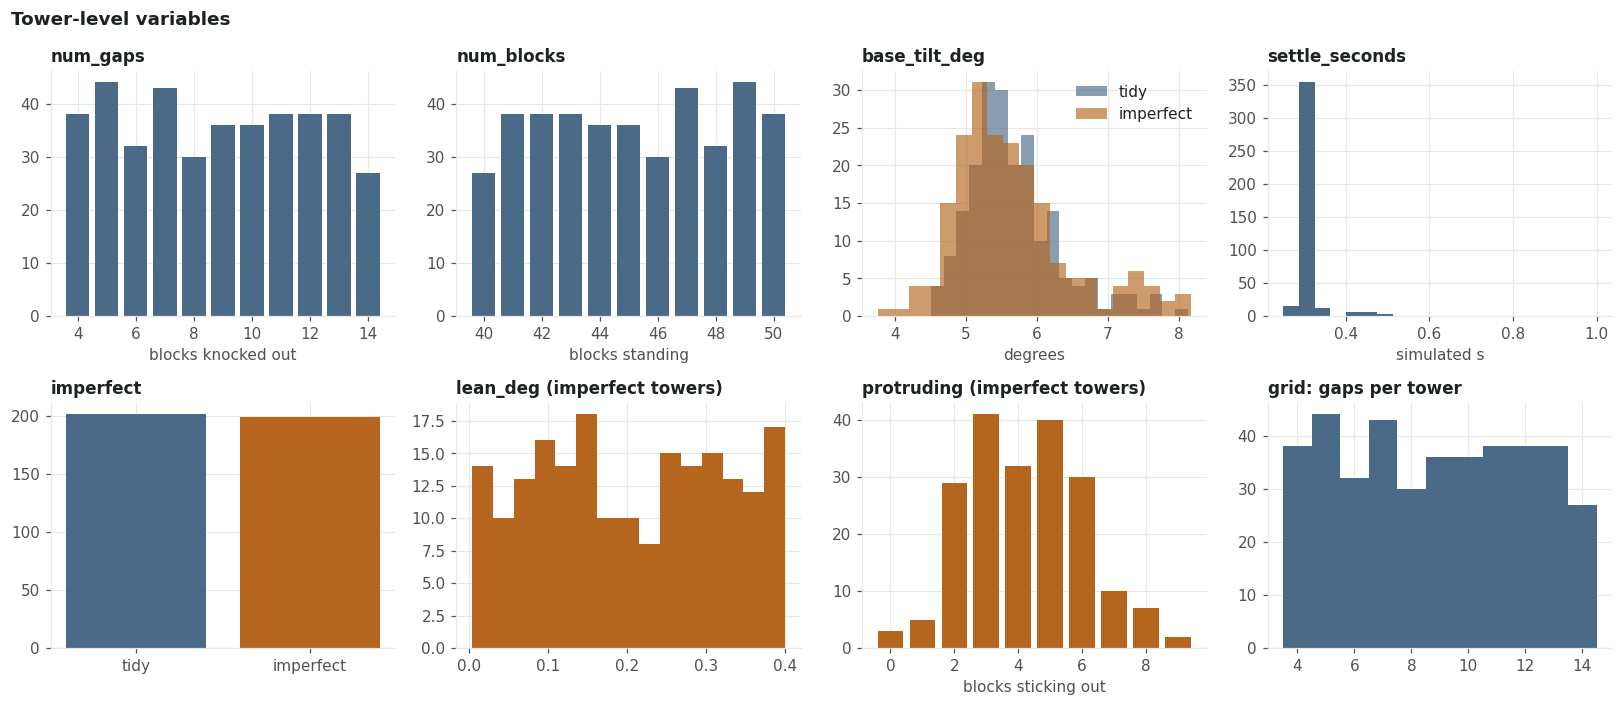

- **Gaps** are spread evenly from 4 to 14 (mean 8.8), so early-, mid- and late-game towers are all represented.
- **Base tilt margin** (how sturdy the untouched tower is): median 5.53°, range 3.75° to 8.18°.
- **Imperfect towers:** 49.8% of towers; lean 0.00° to 0.40°, 4.2 blocks sticking out on average. Tidy towers' median base margin is 5.55°, imperfect 5.47°.
- **Settling** takes 0.30 s of simulated time at the median, so towers start from rest.

In [9]:
# 6a. Tower-level variables
fig, axs = plt.subplots(2, 4, figsize=(15, 6.5))
ax = axs.flat
k = towers.num_gaps.value_counts().sort_index()
ax[0].bar(k.index, k.values, color=NEUTRAL); ax[0].set_title("num_gaps"); ax[0].set_xlabel("blocks knocked out")
k = towers.num_blocks.value_counts().sort_index()
ax[1].bar(k.index, k.values, color=NEUTRAL); ax[1].set_title("num_blocks"); ax[1].set_xlabel("blocks standing")
for kind, c in (("tidy", TIDY), ("imperfect", IMPERFECT)):
    ax[2].hist(towers.loc[towers.kind == kind, "base_tilt_deg"], bins=20, alpha=.65, color=c, label=kind)
ax[2].set_title("base_tilt_deg"); ax[2].set_xlabel("degrees"); ax[2].legend(frameon=False)
ax[3].hist(towers.settle_seconds, bins=20, color=NEUTRAL); ax[3].set_title("settle_seconds"); ax[3].set_xlabel("simulated s")
k = towers.kind.value_counts()
ax[4].bar(k.index, k.values, color=[TIDY if i == "tidy" else IMPERFECT for i in k.index]); ax[4].set_title("imperfect")
ax[5].hist(towers.loc[towers.imperfect, "lean_deg"], bins=15, color=IMPERFECT); ax[5].set_title("lean_deg (imperfect towers)")
k = towers.loc[towers.imperfect, "protruding"].value_counts().sort_index()
ax[6].bar(k.index, k.values, color=IMPERFECT); ax[6].set_title("protruding (imperfect towers)"); ax[6].set_xlabel("blocks sticking out")
ax[7].hist(towers.grid.str.count("0"), bins=np.arange(3.5, 15.5), color=NEUTRAL); ax[7].set_title("grid: gaps per tower")
fig.suptitle("Tower-level variables", fontweight="bold", x=0.01, ha="left"); fig.tight_layout()
save(fig, "6a_tower_variables"); plt.show()

imp = towers[towers.imperfect]
imp_line = (f"{pct(towers.imperfect.mean())} of towers; lean {imp.lean_deg.min():.2f}° to {imp.lean_deg.max():.2f}°, "
            f"{imp.protruding.mean():.1f} blocks sticking out on average. Tidy towers' median base margin is "
            f"{towers.loc[~towers.imperfect, 'base_tilt_deg'].median():.2f}°, imperfect {imp.base_tilt_deg.median():.2f}°."
            if len(imp) else "none in this dataset (it predates imperfect towers).")
say(f"""- **Gaps** are spread evenly from {towers.num_gaps.min()} to {towers.num_gaps.max()} (mean {towers.num_gaps.mean():.1f}), so early-, mid- and late-game towers are all represented.
- **Base tilt margin** (how sturdy the untouched tower is): median {towers.base_tilt_deg.median():.2f}°, range {towers.base_tilt_deg.min():.2f}° to {towers.base_tilt_deg.max():.2f}°.
- **Imperfect towers:** {imp_line}
- **Settling** takes {towers.settle_seconds.median():.2f} s of simulated time at the median, so towers start from rest.""")

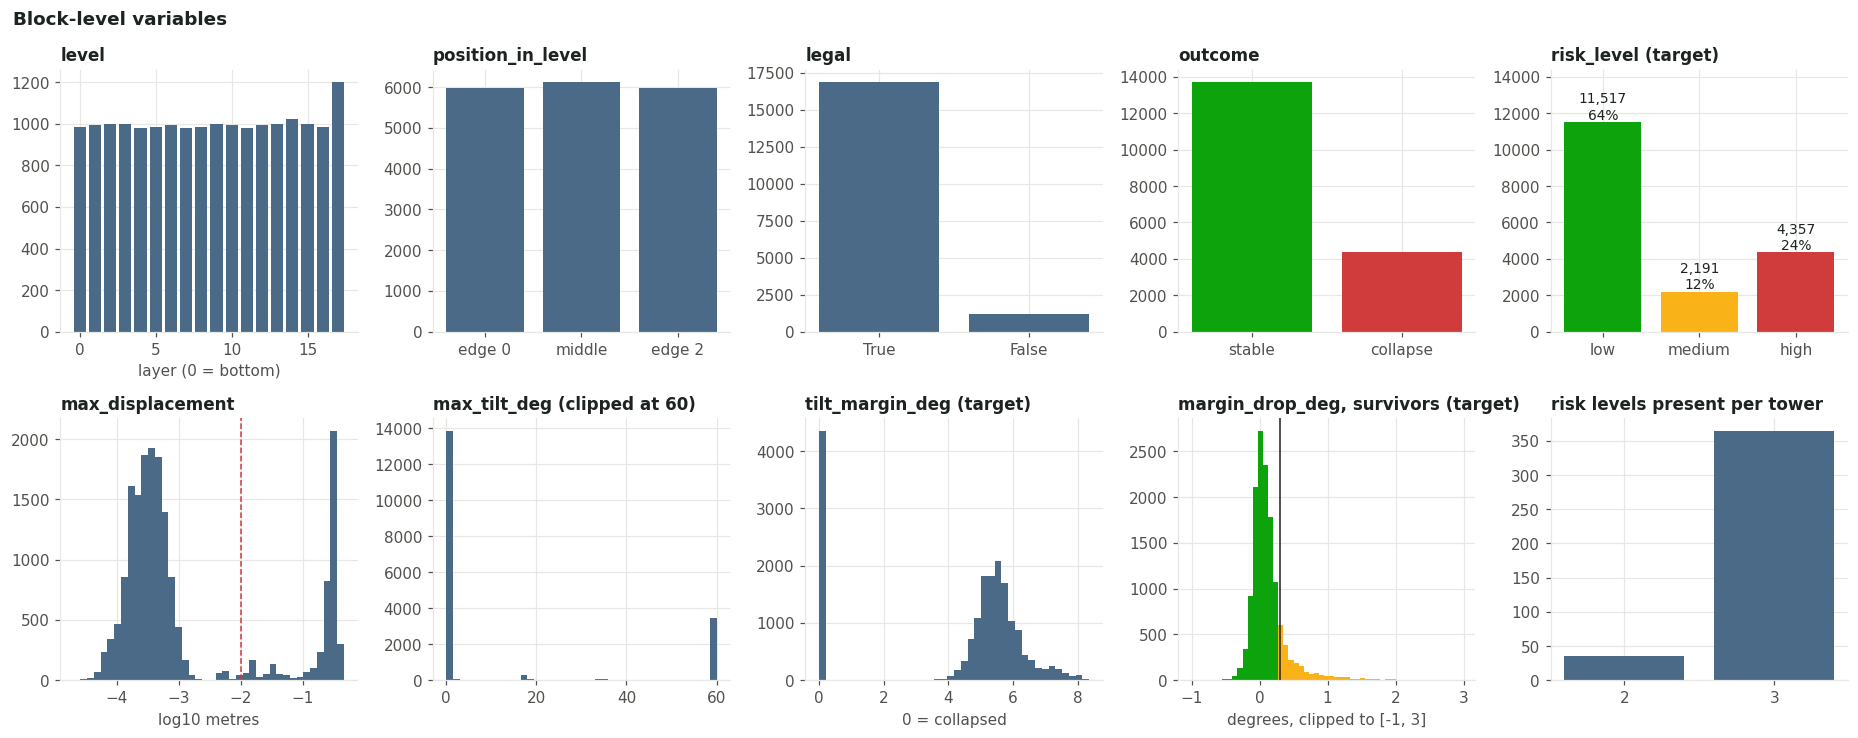

- **Target balance:** 63.8% low, 12.1% medium, 24.1% high. Imbalanced but workable: we will use class weights and macro-F1 so the model cannot score well by mostly predicting low. 91.2% of towers contain all three levels, so risk varies *within* a tower, not just between towers.
- **Outcome:** 24.1% of removals collapse the tower. `max_displacement` is clearly two-humped: survivors move well under 1 cm (dashed line), collapses tens of centimetres. That clean gap is why collapse is easy to label.
- **Margin drop** among survivors is centred near 0 (median 0.07°) with a long right tail: most removals barely matter, a minority weaken the tower a lot. Medium (amber) is that tail beyond 0.3°.
- **Positions:** two edge blocks for every middle block, as in a real tower; every layer holds about the same number of blocks (978 to 1022), except the top one (1200), which is never gapped.

In [10]:
# 6b. Block-level variables (labels)
fig, axs = plt.subplots(2, 5, figsize=(17, 6.8))
ax = axs.flat
k = blocks.level.value_counts().sort_index()
ax[0].bar(k.index, k.values, color=NEUTRAL); ax[0].set_title("level"); ax[0].set_xlabel("layer (0 = bottom)")
k = blocks.position_in_level.map({0: "edge 0", 1: "middle", 2: "edge 2"}).value_counts().reindex(["edge 0", "middle", "edge 2"])
ax[1].bar(k.index, k.values, color=NEUTRAL); ax[1].set_title("position_in_level")
k = blocks.legal.value_counts()
ax[2].bar(k.index.astype(str), k.values, color=NEUTRAL); ax[2].set_title("legal")
k = blocks.outcome.value_counts()
ax[3].bar(k.index, k.values, color=[COL["high"] if i == "collapse" else COL["low"] for i in k.index]); ax[3].set_title("outcome")
k = blocks.risk_level.value_counts().reindex(RISK)
bars = ax[4].bar(k.index, k.values, color=[COL[r] for r in RISK]); ax[4].set_title("risk_level (target)")
for b, v in zip(bars, k.values):
    ax[4].text(b.get_x() + b.get_width() / 2, v, f"{v:,}\n{v / k.sum():.0%}", ha="center", va="bottom", fontsize=9)
ax[4].set_ylim(0, k.max() * 1.25)
ax[5].hist(np.log10(blocks.max_displacement.clip(lower=1e-6)), bins=40, color=NEUTRAL)
ax[5].set_title("max_displacement"); ax[5].set_xlabel("log10 metres"); ax[5].axvline(np.log10(0.01), color=COL["high"], ls="--", lw=1)
ax[6].hist(blocks.max_tilt_deg.clip(upper=60), bins=40, color=NEUTRAL); ax[6].set_title("max_tilt_deg (clipped at 60)")
ax[7].hist(blocks.tilt_margin_deg, bins=40, color=NEUTRAL); ax[7].set_title("tilt_margin_deg (target)"); ax[7].set_xlabel("0 = collapsed")
s = blocks.loc[blocks.survived, "margin_drop_deg"].clip(-1, 3)
ax[8].hist(s, bins=np.arange(-1, 3.05, 0.075), color=COL["low"])
ax[8].hist(s[s >= MEDIUM_DROP_DEG], bins=np.arange(-1, 3.05, 0.075), color=COL["medium"])
ax[8].axvline(MEDIUM_DROP_DEG, color=INK, lw=1); ax[8].set_title("margin_drop_deg, survivors (target)")
ax[8].set_xlabel("degrees, clipped to [-1, 3]")
k = blocks.groupby("tower_id").risk_level.nunique().value_counts().sort_index()
ax[9].bar(k.index.astype(str), k.values, color=NEUTRAL); ax[9].set_title("risk levels present per tower")
fig.suptitle("Block-level variables", fontweight="bold", x=0.01, ha="left"); fig.tight_layout()
save(fig, "6b_block_variables"); plt.show()

share = blocks.risk_level.value_counts(normalize=True).reindex(RISK)
three = blocks.groupby("tower_id").risk_level.nunique().eq(3).mean()
surv = blocks[blocks.survived]
say(f"""- **Target balance:** {pct(share['low'])} low, {pct(share['medium'])} medium, {pct(share['high'])} high. Imbalanced but workable: we will use class weights and macro-F1 so the model cannot score well by mostly predicting low. {pct(three)} of towers contain all three levels, so risk varies *within* a tower, not just between towers.
- **Outcome:** {pct(blocks.outcome.eq('collapse').mean())} of removals collapse the tower. `max_displacement` is clearly two-humped: survivors move well under 1 cm (dashed line), collapses tens of centimetres. That clean gap is why collapse is easy to label.
- **Margin drop** among survivors is centred near 0 (median {surv.margin_drop_deg.median():.2f}°) with a long right tail: most removals barely matter, a minority weaken the tower a lot. Medium (amber) is that tail beyond {MEDIUM_DROP_DEG}°.
- **Positions:** two edge blocks for every middle block, as in a real tower; every layer holds about the same number of blocks ({blocks.level[blocks.level < LAYERS - 1].value_counts().min()} to {blocks.level[blocks.level < LAYERS - 1].value_counts().max()}), except the top one ({(blocks.level == LAYERS - 1).sum()}), which is never gapped.""")

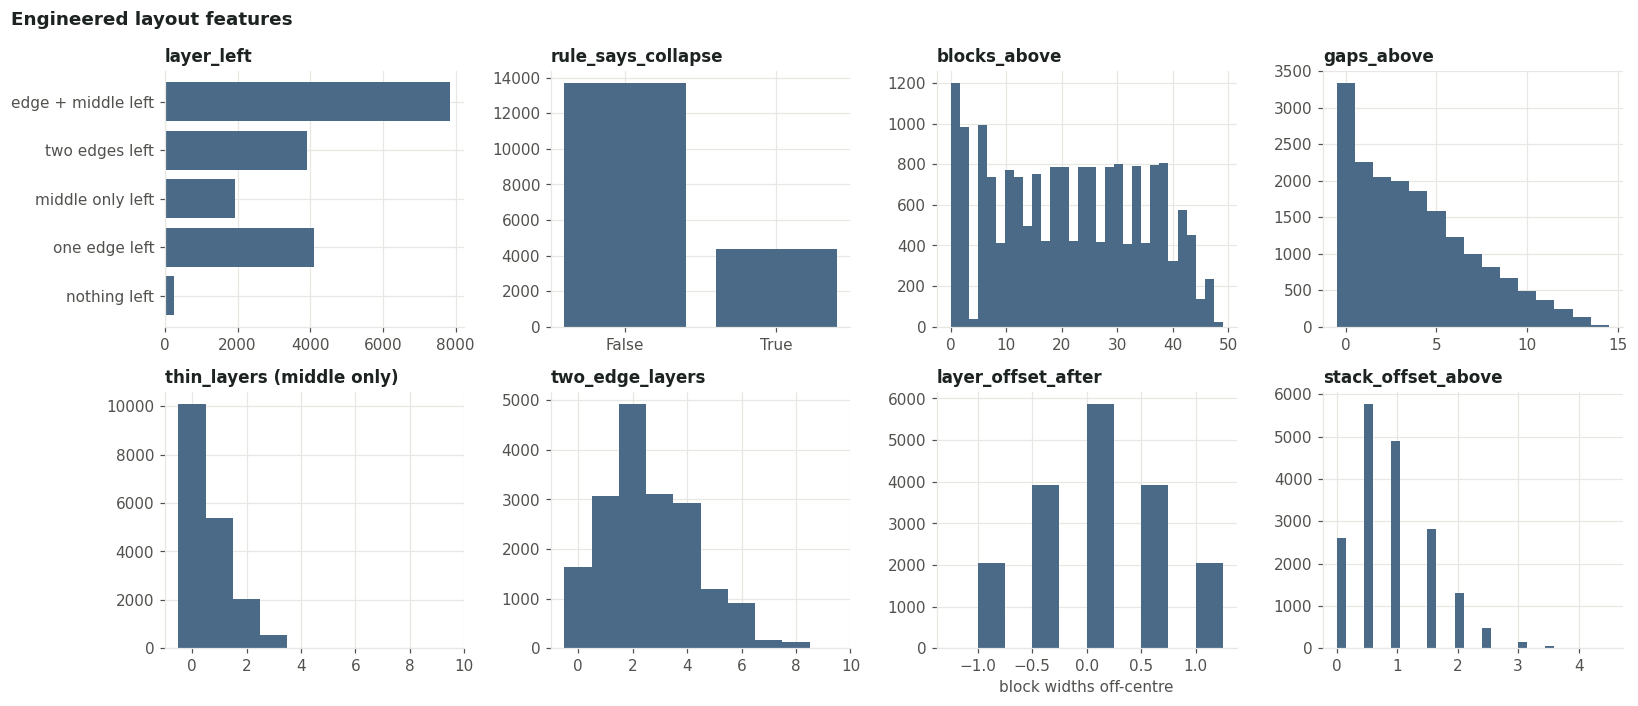

- Most removals leave an **edge + middle** layer (43.4%); the rule of thumb flags 24.1% of removals as collapses.
- **Load** (`blocks_above`) spans 0 to 49, roughly uniform with height, so the model sees light and heavy blocks alike.
- **Off-centre support** is common: 43.4% of removals leave the layer half a block off-centre, the situation behind most medium-risk edge blocks.

In [11]:
# 6c. Engineered layout features
fig, axs = plt.subplots(2, 4, figsize=(15, 6.5))
ax = axs.flat
order = ["edge + middle left", "two edges left", "middle only left", "one edge left", "nothing left"]
k = blocks.layer_left.value_counts().reindex(order).fillna(0)
ax[0].barh(k.index, k.values, color=NEUTRAL); ax[0].set_title("layer_left"); ax[0].invert_yaxis()
k = blocks.rule_says_collapse.value_counts()
ax[1].bar(k.index.astype(str), k.values, color=NEUTRAL); ax[1].set_title("rule_says_collapse")
ax[2].hist(blocks.blocks_above, bins=30, color=NEUTRAL); ax[2].set_title("blocks_above")
ax[3].hist(blocks.gaps_above, bins=np.arange(-.5, 15.5), color=NEUTRAL); ax[3].set_title("gaps_above")
ax[4].hist(blocks.thin_layers, bins=np.arange(-.5, 10.5), color=NEUTRAL); ax[4].set_title("thin_layers (middle only)")
ax[5].hist(blocks.two_edge_layers, bins=np.arange(-.5, 10.5), color=NEUTRAL); ax[5].set_title("two_edge_layers")
ax[6].hist(blocks.layer_offset_after.dropna(), bins=np.arange(-1.25, 1.3, 0.25), color=NEUTRAL)
ax[6].set_title("layer_offset_after"); ax[6].set_xlabel("block widths off-centre")
ax[7].hist(blocks.stack_offset_above, bins=30, color=NEUTRAL); ax[7].set_title("stack_offset_above")
fig.suptitle("Engineered layout features", fontweight="bold", x=0.01, ha="left"); fig.tight_layout()
save(fig, "6c_engineered_features"); plt.show()

say(f"""- Most removals leave an **edge + middle** layer ({pct(blocks.layer_left.eq('edge + middle left').mean())}); the rule of thumb flags {pct(blocks.rule_says_collapse.mean())} of removals as collapses.
- **Load** (`blocks_above`) spans 0 to {blocks.blocks_above.max()}, roughly uniform with height, so the model sees light and heavy blocks alike.
- **Off-centre support** is common: {pct(blocks.layer_offset_after.abs().eq(0.5).mean())} of removals leave the layer half a block off-centre, the situation behind most medium-risk edge blocks.""")

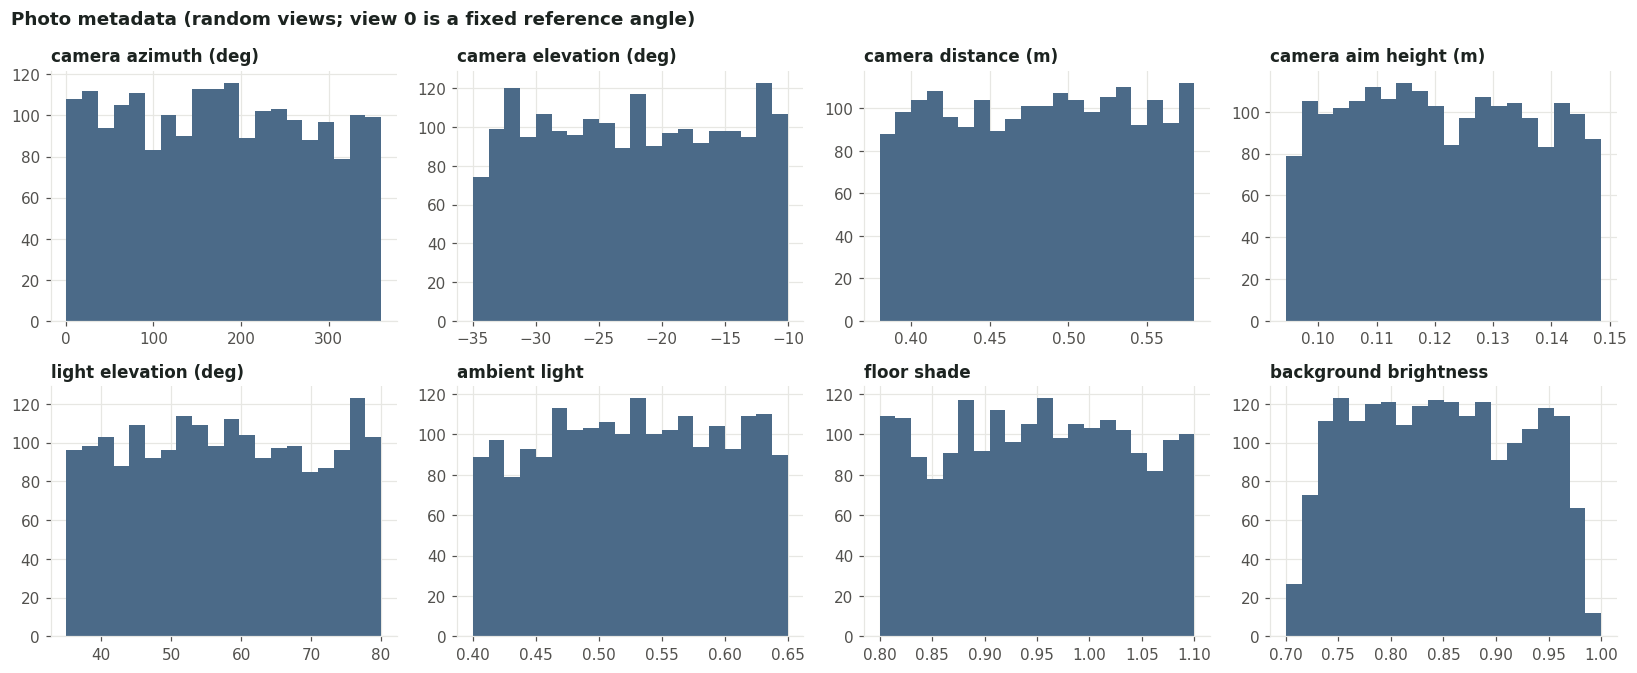

Camera azimuth covers 0° to 360° (every side of the tower), elevation -35° to -10° (looking down), distance 0.38 to 0.58 m. All roughly uniform: the randomisation does what it should, with no favoured angle the detector could over-fit to.

In [12]:
# 6d. Photo metadata: camera and lighting (domain randomisation)
cols = [("cam_azimuth_deg", "camera azimuth (deg)"), ("cam_elevation_deg", "camera elevation (deg)"),
        ("cam_distance_m", "camera distance (m)"), ("cam_target_z_m", "camera aim height (m)"),
        ("light_elevation_deg", "light elevation (deg)"), ("ambient", "ambient light"),
        ("ground_shade", "floor shade"), ("background_brightness", "background brightness")]
fig, axs = plt.subplots(2, 4, figsize=(15, 6.2))
rand = views[views.view > 0]
for ax, (c, t) in zip(axs.flat, cols):
    if c in rand:
        ax.hist(rand[c].dropna(), bins=20, color=NEUTRAL)
    ax.set_title(t)
fig.suptitle("Photo metadata (random views; view 0 is a fixed reference angle)", fontweight="bold", x=0.01, ha="left")
fig.tight_layout(); save(fig, "6d_camera_lighting"); plt.show()
say(f"Camera azimuth covers {rand.cam_azimuth_deg.min():.0f}° to {rand.cam_azimuth_deg.max():.0f}° (every side of the tower), "
    f"elevation {rand.cam_elevation_deg.min():.0f}° to {rand.cam_elevation_deg.max():.0f}° (looking down), distance "
    f"{rand.cam_distance_m.min():.2f} to {rand.cam_distance_m.max():.2f} m. All roughly uniform: the randomisation does what it should, "
    f"with no favoured angle the detector could over-fit to.")

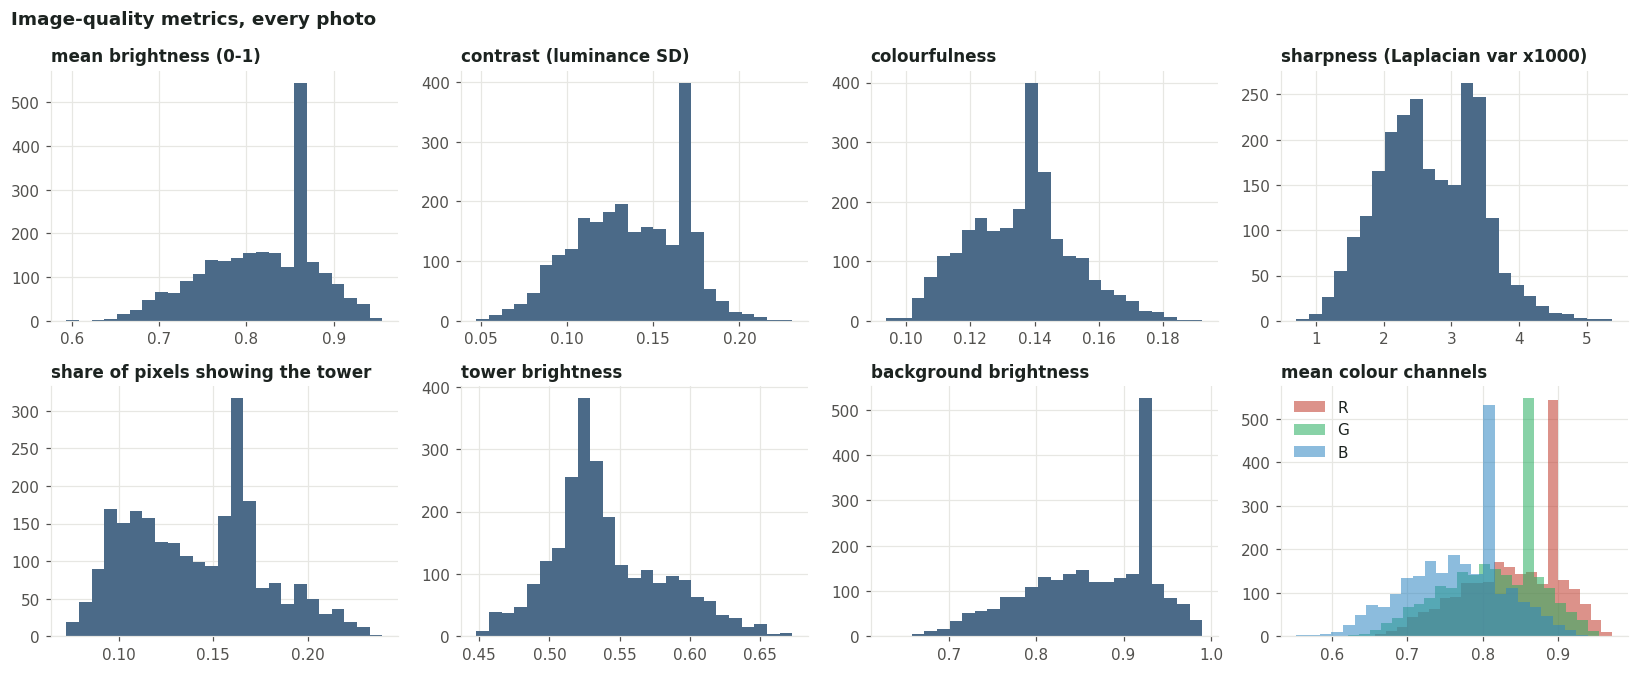

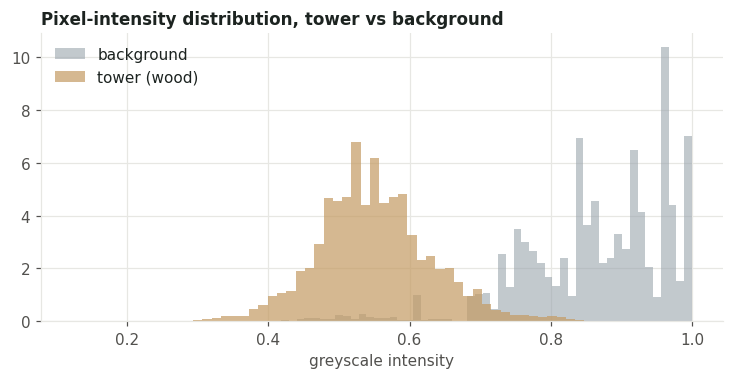

- **Brightness** 0.59 to 0.96 (median 0.83) and **contrast** 0.05 to 0.23: no photo is blank, black or saturated.
- **The tower fills** 7.2% to 23.9% of the frame (median 14.2%), set by camera distance. Small towers are the hardest case for the detector.
- **Sharpness** never collapses towards zero: renders have no motion blur. Real phone photos will be blurrier, one of the sim-to-real gaps we must test.
- **Colour:** wood pixels separate cleanly from background in intensity (above), and red > green > blue on average, as expected for wood. Real backgrounds will be more cluttered than our plain floors, another gap to cover with fine-tuning.

In [13]:
# 6e. Image-quality metrics (pixel intensity, contrast, colour, sharpness, coverage)
metrics = [("brightness", "mean brightness (0-1)"), ("contrast", "contrast (luminance SD)"),
           ("colourfulness", "colourfulness"), ("sharpness", "sharpness (Laplacian var x1000)"),
           ("tower_fraction", "share of pixels showing the tower"), ("tower_brightness", "tower brightness"),
           ("background_lum", "background brightness")]
fig, axs = plt.subplots(2, 4, figsize=(15, 6.2))
for ax, (c, t) in zip(axs.flat, metrics):
    ax.hist(views[c].dropna(), bins=25, color=NEUTRAL); ax.set_title(t)
ax = axs.flat[7]
for ch, c in (("mean_r", "#c0392b"), ("mean_g", "#27ae60"), ("mean_b", "#2e86c1")):
    ax.hist(views[ch], bins=25, alpha=.55, color=c, label=ch[-1].upper())
ax.set_title("mean colour channels"); ax.legend(frameon=False)
fig.suptitle("Image-quality metrics, every photo", fontweight="bold", x=0.01, ha="left")
fig.tight_layout(); save(fig, "6e_image_quality"); plt.show()

# Pixel-intensity histogram across a sample of photos, tower pixels vs background
lum_t, lum_b = [], []
for t, v in zip(views.tower_id.head(120), views.view.head(120)):
    name = f"tower_{int(t):04d}_v{int(v)}"
    rgb = np.asarray(Image.open(DATA / "images" / f"{name}.png").convert("L"), dtype=np.float32) / 255
    seg = np.asarray(Image.open(DATA / "masks" / f"{name}_seg.png")) > 0
    lum_t.append(rgb[seg][::7]); lum_b.append(rgb[~seg][::29])
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.hist(np.concatenate(lum_b), bins=60, density=True, alpha=.6, color="#9aa5ad", label="background")
ax.hist(np.concatenate(lum_t), bins=60, density=True, alpha=.7, color="#c49a62", label="tower (wood)")
ax.set_title("Pixel-intensity distribution, tower vs background"); ax.set_xlabel("greyscale intensity"); ax.legend(frameon=False)
save(fig, "6e_pixel_intensity"); plt.show()

dark = views.brightness.lt(views.brightness.quantile(.02))
say(f"""- **Brightness** {views.brightness.min():.2f} to {views.brightness.max():.2f} (median {views.brightness.median():.2f}) and **contrast** {views.contrast.min():.2f} to {views.contrast.max():.2f}: no photo is blank, black or saturated.
- **The tower fills** {pct(views.tower_fraction.min())} to {pct(views.tower_fraction.max())} of the frame (median {pct(views.tower_fraction.median())}), set by camera distance. Small towers are the hardest case for the detector.
- **Sharpness** never collapses towards zero: renders have no motion blur. Real phone photos will be blurrier, one of the sim-to-real gaps we must test.
- **Colour:** wood pixels separate cleanly from background in intensity (above), and red > green > blue on average, as expected for wood. Real backgrounds will be more cluttered than our plain floors, another gap to cover with fine-tuning.""")

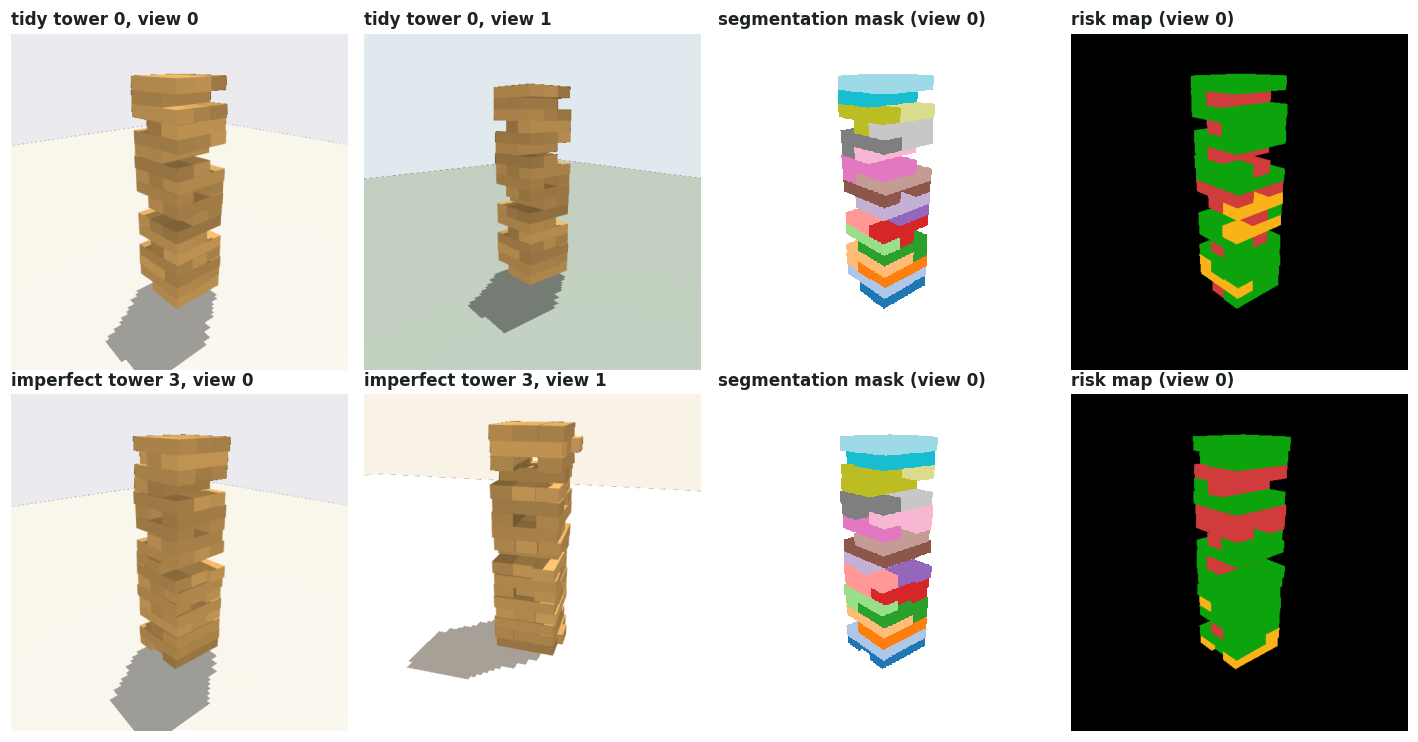

In [14]:
# 6f. Example photos with their segmentation mask and risk map
RISK_RGB = np.array([[0, 0, 0], [12, 163, 12], [250, 178, 25], [208, 59, 59]], dtype=np.uint8)
picks = []
for kind in ("tidy", "imperfect"):
    t = towers.loc[towers.kind == kind, "tower_id"]
    if len(t):
        picks.append((kind, int(t.iloc[0])))
fig, axs = plt.subplots(len(picks), 4, figsize=(13, 3.4 * len(picks)), squeeze=False)
for row, (kind, t) in zip(axs, picks):
    for ax, v in zip(row[:2], (0, 1)):
        ax.imshow(Image.open(DATA / "images" / f"tower_{t:04d}_v{v}.png")); ax.set_title(f"{kind} tower {t}, view {v}")
    seg = np.asarray(Image.open(DATA / "masks" / f"tower_{t:04d}_v0_seg.png"))
    risk = np.asarray(Image.open(DATA / "risk" / f"tower_{t:04d}_v0_risk.png"))
    row[2].imshow(np.ma.masked_equal(seg, 0), cmap="tab20", interpolation="nearest"); row[2].set_title("segmentation mask (view 0)")
    row[3].imshow(RISK_RGB[risk]); row[3].set_title("risk map (view 0)")
    for ax in row:
        ax.axis("off")
fig.tight_layout(); save(fig, "6f_examples"); plt.show()

### 7. Perform bi-variate analysis on some of the variables. You do not need to present the analysis of every pair of variables; only focus on the pairs you believe are worth investigating and explain. For each pair, describe the relationship between the two variables.

**Response.** We focus on pairs that tell us what drives risk (what the model must learn), whether imperfect towers behave differently, and whether the photos are fit for the detector.

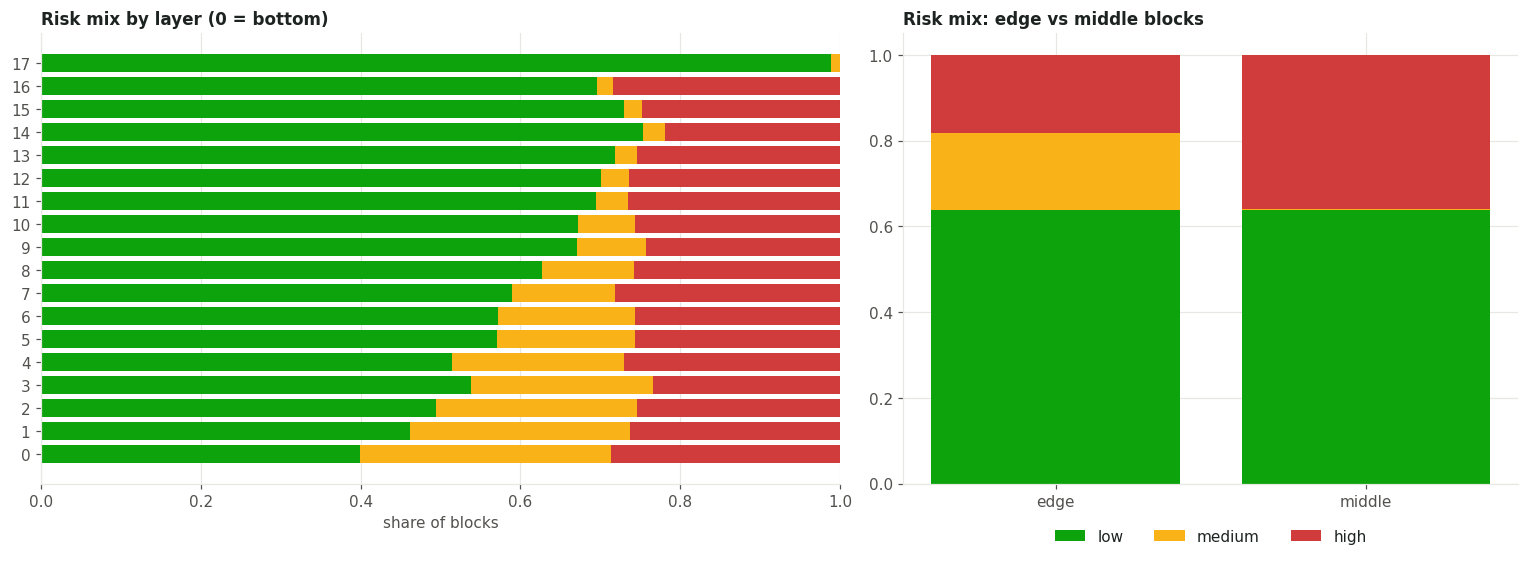

**Height → risk.** Medium risk is 31.5% in the bottom layer and 2.0% in layer 16: lower blocks carry more of the tower, so removing one shifts more weight. High risk stays roughly flat with height, because collapse depends on the block's own layer, not its height. The top layer is almost never high: nothing rests on it.

**Position → risk.** Edge blocks are medium 18.2% of the time and middle blocks 0.3%, but middle blocks are high 35.9% vs 18.1% for edges. Taking an edge shifts the layer's support off-centre (medium); taking a middle is safe unless it leaves a single edge (high).

In [15]:
def stacked(ax, table, title, horizontal=True):
    table = table.reindex(columns=RISK).fillna(0)
    left = np.zeros(len(table))
    for r in RISK:
        if horizontal:
            ax.barh(table.index.astype(str), table[r], left=left, color=COL[r], label=r)
        else:
            ax.bar(table.index.astype(str), table[r], bottom=left, color=COL[r], label=r)
        left += table[r].values
    ax.set_title(title)

# 7a. Risk vs height and vs position
fig, axs = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [1.3, 1]})
by_level = pd.crosstab(blocks.level, blocks.risk_level, normalize="index")
stacked(axs[0], by_level, "Risk mix by layer (0 = bottom)", horizontal=True); axs[0].set_xlabel("share of blocks")
by_pos = pd.crosstab(blocks.is_edge.map({True: "edge", False: "middle"}), blocks.risk_level, normalize="index")
stacked(axs[1], by_pos, "Risk mix: edge vs middle blocks", horizontal=False)
axs[1].legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.07))
fig.tight_layout(); save(fig, "7a_risk_height_position"); plt.show()

lo, hi = by_level.index.min(), by_level.index.max() - 1
say(f"""**Height → risk.** Medium risk is {pct(by_level.loc[lo, 'medium'])} in the bottom layer and {pct(by_level.loc[hi, 'medium'])} in layer {hi}: lower blocks carry more of the tower, so removing one shifts more weight. High risk stays roughly flat with height, because collapse depends on the block's own layer, not its height. The top layer is almost never high: nothing rests on it.

**Position → risk.** Edge blocks are medium {pct(by_pos.loc['edge', 'medium'])} of the time and middle blocks {pct(by_pos.loc['middle', 'medium'])}, but middle blocks are high {pct(by_pos.loc['middle', 'high'])} vs {pct(by_pos.loc['edge', 'high'])} for edges. Taking an edge shifts the layer's support off-centre (medium); taking a middle is safe unless it leaves a single edge (high).""")

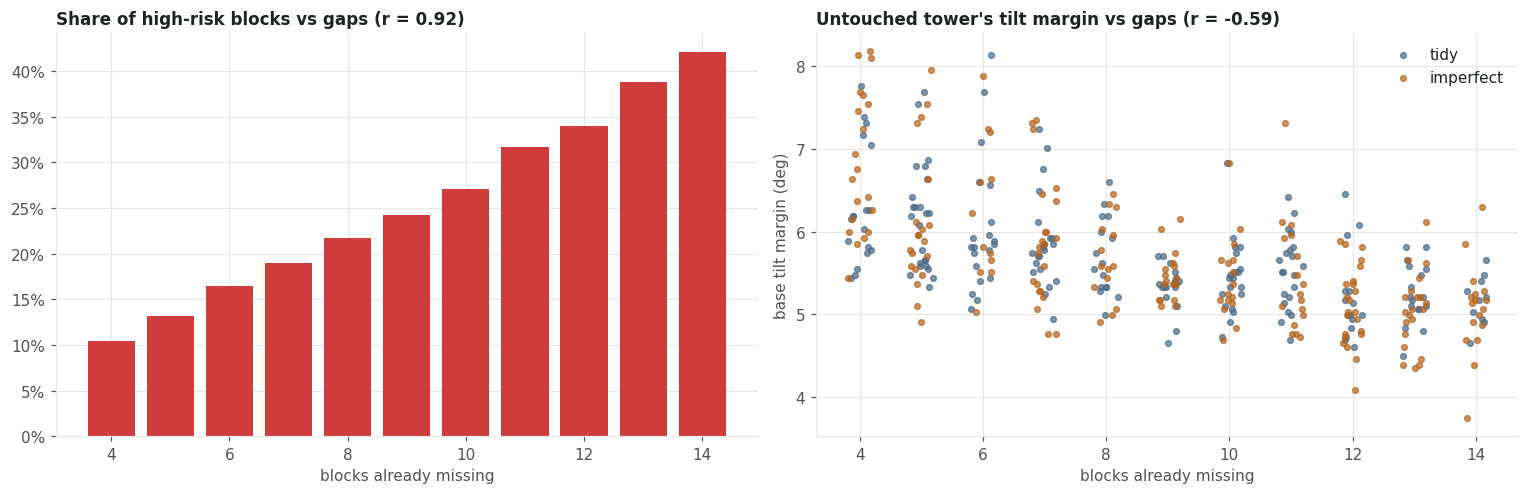

**Gaps → danger.** The share of high-risk blocks rises from 10.5% with 4 gaps to 42.0% with 14 (r = 0.92): every gap removes a support that a later removal could need.

**Gaps → sturdiness.** The untouched tower's tilt margin falls as gaps grow (r = -0.59). Gappier towers start closer to tipping, so the same removal is more likely to push them over.

In [16]:
# 7b. Gaps vs high risk, and the tower's own sturdiness
t = blocks.groupby("tower_id").agg(gaps=("num_gaps", "first"), high=("risk_level", lambda s: s.eq("high").mean()),
                                   medium=("risk_level", lambda s: s.eq("medium").mean()),
                                   kind=("kind", "first"), base=("base_tilt_deg", "first"))
r_high = np.corrcoef(t.gaps, t.high)[0, 1]
r_base = np.corrcoef(t.gaps, t.base)[0, 1]
fig, axs = plt.subplots(1, 2, figsize=(14, 4.6))
g = t.groupby("gaps").high.mean()
axs[0].bar(g.index, g.values, color=COL["high"]); axs[0].set_title(f"Share of high-risk blocks vs gaps (r = {r_high:.2f})")
axs[0].set_xlabel("blocks already missing"); axs[0].yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
for kind, c in (("tidy", TIDY), ("imperfect", IMPERFECT)):
    s = t[t.kind == kind]
    axs[1].scatter(s.gaps + np.random.default_rng(1).uniform(-.2, .2, len(s)), s.base, s=14, alpha=.7, color=c, label=kind)
axs[1].set_title(f"Untouched tower's tilt margin vs gaps (r = {r_base:.2f})"); axs[1].set_xlabel("blocks already missing")
axs[1].set_ylabel("base tilt margin (deg)"); axs[1].legend(frameon=False)
fig.tight_layout(); save(fig, "7b_gaps"); plt.show()
say(f"""**Gaps → danger.** The share of high-risk blocks rises from {pct(g.iloc[0])} with {g.index[0]} gaps to {pct(g.iloc[-1])} with {g.index[-1]} (r = {r_high:.2f}): every gap removes a support that a later removal could need.

**Gaps → sturdiness.** The untouched tower's tilt margin falls as gaps grow (r = {r_base:.2f}). Gappier towers start closer to tipping, so the same removal is more likely to push them over.""")

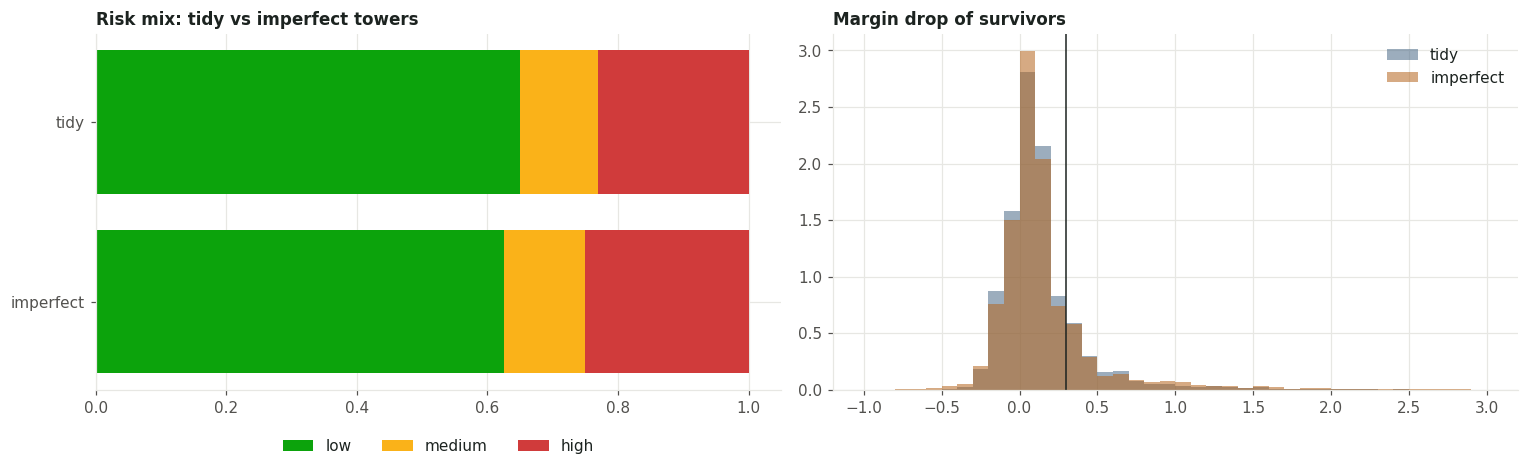

**Imperfect → risk.** Tidy towers: 65.0% low / 11.9% medium / 23.1% high. Imperfect: 62.5% / 12.4% / 25.1%. The difference is small. The rule of thumb matches the physics on 100.0% of tidy and 100.0% of imperfect removals, so imperfection does not change high risk at all; any effect has to be on medium. We will test whether lean and sticking-out blocks (both measurable from a photo) improve medium predictions, and report results for tidy and imperfect towers separately.

In [17]:
# 7c. Tidy vs imperfect towers
fig, axs = plt.subplots(1, 2, figsize=(14, 4.4))
mix = pd.crosstab(blocks.kind, blocks.risk_level, normalize="index")
stacked(axs[0], mix, "Risk mix: tidy vs imperfect towers", horizontal=True)
axs[0].legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.1))
for kind, c in (("tidy", TIDY), ("imperfect", IMPERFECT)):
    s = blocks.loc[blocks.survived & blocks.kind.eq(kind), "margin_drop_deg"].clip(-1, 3)
    if len(s):
        axs[1].hist(s, bins=np.arange(-1, 3.05, 0.1), density=True, alpha=.55, color=c, label=kind)
axs[1].axvline(MEDIUM_DROP_DEG, color=INK, lw=1); axs[1].set_title("Margin drop of survivors"); axs[1].legend(frameon=False)
fig.tight_layout(); save(fig, "7c_tidy_vs_imperfect"); plt.show()

if blocks.imperfect.any() and (~blocks.imperfect).any():
    rule_by_kind = (blocks.rule_says_collapse == blocks.outcome.eq("collapse")).groupby(blocks.kind).mean()
    say(f"""**Imperfect → risk.** Tidy towers: {pct(mix.loc['tidy', 'low'])} low / {pct(mix.loc['tidy', 'medium'])} medium / {pct(mix.loc['tidy', 'high'])} high. Imperfect: {pct(mix.loc['imperfect', 'low'])} / {pct(mix.loc['imperfect', 'medium'])} / {pct(mix.loc['imperfect', 'high'])}. The difference is small. The rule of thumb matches the physics on {pct(rule_by_kind['tidy'])} of tidy and {pct(rule_by_kind['imperfect'])} of imperfect removals, so imperfection {'does not change high risk at all' if rule_by_kind.min() == 1 else 'barely changes high risk'}; any effect has to be on medium. We will test whether lean and sticking-out blocks (both measurable from a photo) improve medium predictions, and report results for tidy and imperfect towers separately.""")
else:
    say("This dataset has only one kind of tower, so tidy and imperfect cannot be compared yet.")

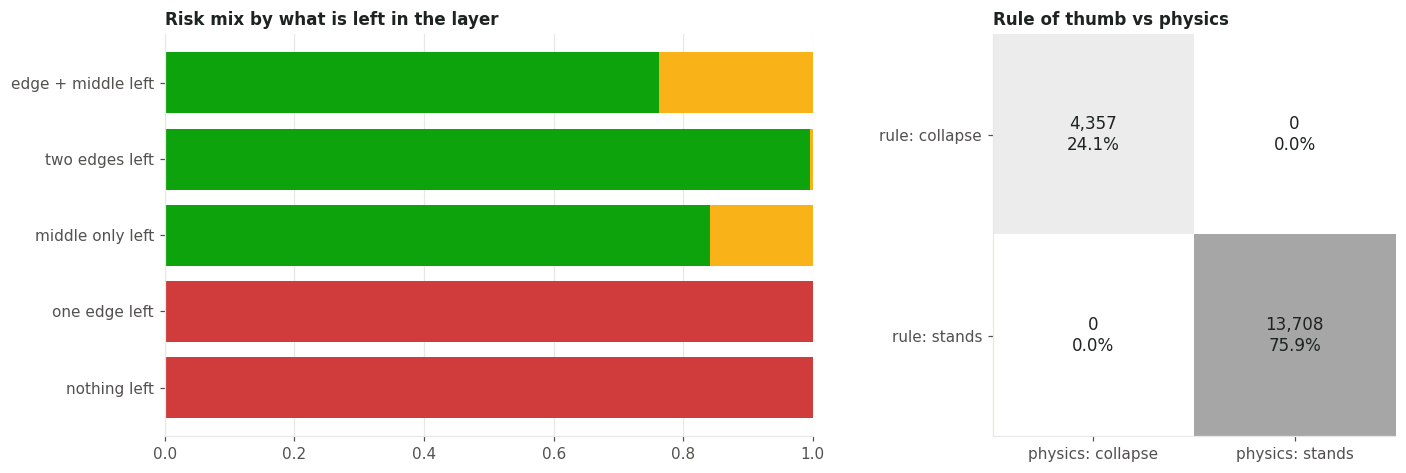

**What's left in the layer → risk.** This one variable fully decides high risk: "one edge left" and "nothing left" are always high, and the rule of thumb built on it agrees with the physics on 100.0% of removals. But it says little about **medium**, which spreads across "edge + middle" and "two edges" layers. Medium depends on the rest of the tower, so a model needs the wider features (load, gaps, off-centre stack), not just the block's own layer.

In [18]:
# 7d. What is left in the layer -> risk, and the rule of thumb vs physics
fig, axs = plt.subplots(1, 2, figsize=(14, 4.4))
lay = pd.crosstab(blocks.layer_left, blocks.risk_level, normalize="index").reindex(
    [o for o in ["edge + middle left", "two edges left", "middle only left", "one edge left", "nothing left"]
     if o in set(blocks.layer_left)])
stacked(axs[0], lay, "Risk mix by what is left in the layer", horizontal=True); axs[0].invert_yaxis()
cm = pd.crosstab(blocks.rule_says_collapse.map({True: "rule: collapse", False: "rule: stands"}),
                 blocks.outcome.map({"collapse": "physics: collapse", "stable": "physics: stands"}))
axs[1].imshow(cm.values, cmap="Greys", alpha=.35)
for (i, j), v in np.ndenumerate(cm.values):
    axs[1].text(j, i, f"{v:,}\n{v / cm.values.sum():.1%}", ha="center", va="center", fontsize=11)
axs[1].set_xticks(range(cm.shape[1]), cm.columns); axs[1].set_yticks(range(cm.shape[0]), cm.index)
axs[1].grid(False); axs[1].set_title("Rule of thumb vs physics")
fig.tight_layout(); save(fig, "7d_layer_and_rule"); plt.show()
agree = np.trace(cm.values) / cm.values.sum()
say(f"""**What's left in the layer → risk.** This one variable {'fully' if agree == 1 else 'nearly'} decides high risk: "one edge left" and "nothing left" are {'always' if agree == 1 else 'almost always'} high, and the rule of thumb built on it agrees with the physics on {pct(agree)} of removals. But it says little about **medium**, which spreads across "edge + middle" and "two edges" layers. Medium depends on the rest of the tower, so a model needs the wider features (load, gaps, off-centre stack), not just the block's own layer.""")

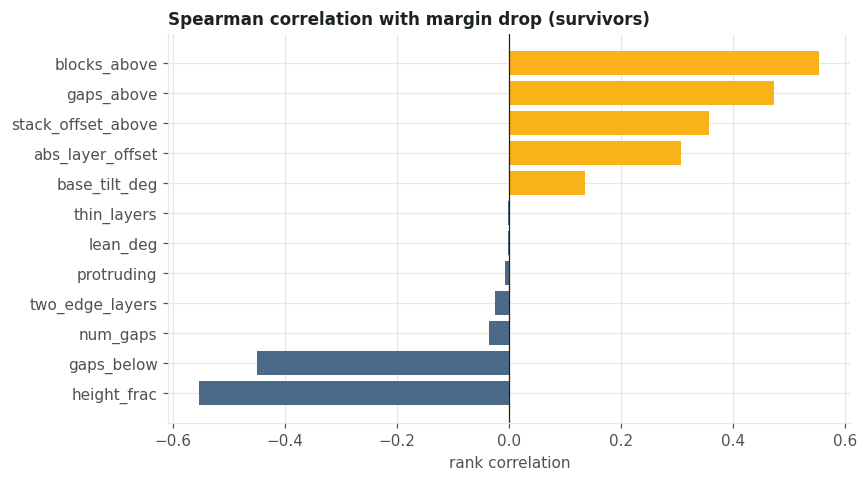

**Features → margin drop.** The strongest single links are blocks_above (ρ = 0.55) and height_frac (ρ = -0.55). No single feature is strong on its own (all |ρ| ≤ 0.55), which is the case for a model that combines them rather than a one-variable rule.

**Features → each other (redundancy).** The most correlated feature pairs are height_frac & blocks_above (ρ = -0.99), height_frac & gaps_above (ρ = -0.86), lean_deg & protruding (ρ = 0.85), blocks_above & gaps_below (ρ = -0.83). Height and load measure much the same thing, so a linear model should keep one; tree models cope with both.

In [19]:
# 7e. Which features move with the margin drop? (survivors, Spearman rank correlation)
feats = ["height_frac", "blocks_above", "gaps_above", "gaps_below", "num_gaps", "thin_layers",
         "two_edge_layers", "layer_offset_after", "stack_offset_above", "base_tilt_deg", "lean_deg", "protruding"]
s = blocks[blocks.survived].copy()
s["abs_layer_offset"] = s.layer_offset_after.abs()
feats = [f if f != "layer_offset_after" else "abs_layer_offset" for f in feats]
rho = s[feats + ["margin_drop_deg"]].rank().corr().loc[feats, "margin_drop_deg"].sort_values()
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.barh(rho.index, rho.values, color=[COL["medium"] if v > 0 else NEUTRAL for v in rho.values])
ax.axvline(0, color=INK, lw=.8); ax.set_title("Spearman correlation with margin drop (survivors)")
ax.set_xlabel("rank correlation")
save(fig, "7e_feature_correlation"); plt.show()

corr = s[feats].rank().corr()
pairs = corr.where(np.triu(np.ones(corr.shape, bool), 1)).stack().sort_values(key=abs, ascending=False).head(4)
say(f"""**Features → margin drop.** The strongest single links are {rho.abs().sort_values(ascending=False).index[0]} (ρ = {rho[rho.abs().idxmax()]:.2f}) and {rho.abs().sort_values(ascending=False).index[1]} (ρ = {rho[rho.abs().sort_values(ascending=False).index[1]]:.2f}). No single feature is strong on its own (all |ρ| ≤ {rho.abs().max():.2f}), which is the case for a model that combines them rather than a one-variable rule.

**Features → each other (redundancy).** The most correlated feature pairs are {', '.join(f'{a} & {b} (ρ = {v:.2f})' for (a, b), v in pairs.items())}. Height and load measure much the same thing, so a linear model should keep one; tree models cope with both.""")

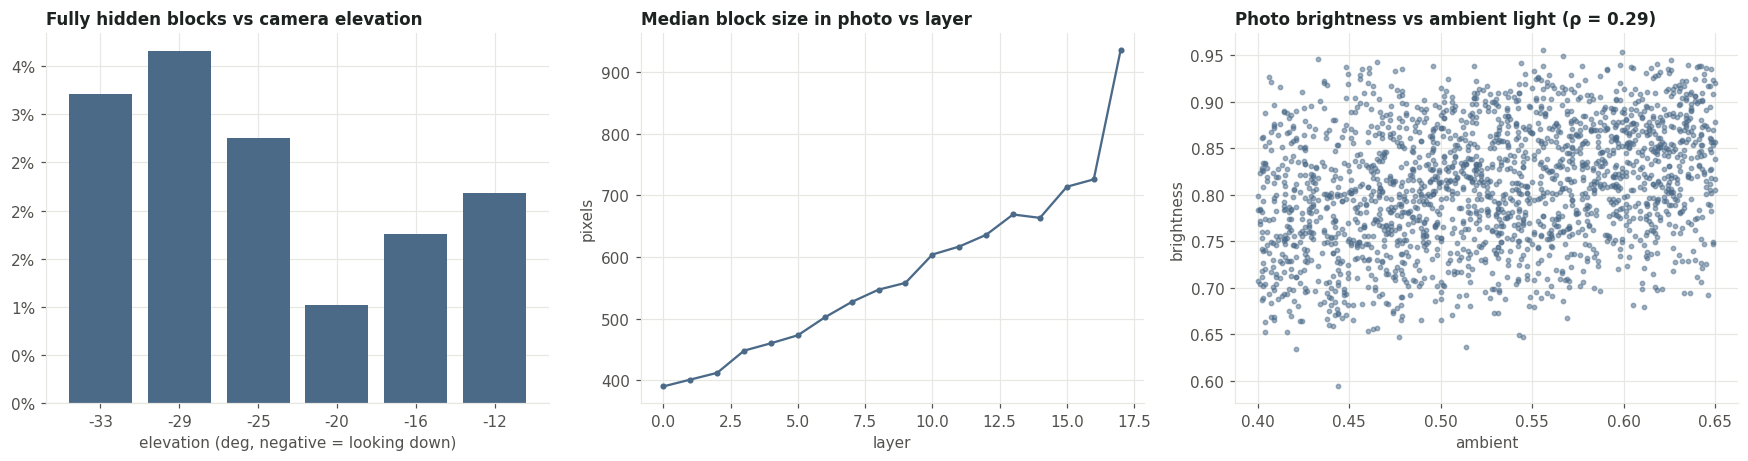

**Camera angle → occlusion.** Hidden blocks change with camera elevation (1.0% to 3.7%), so the detector should see the full range of angles in training, which the randomisation provides.

**Layer → apparent size.** Blocks span a range of pixel sizes with height (perspective), so the detector must handle small and large instances.

**Lighting → brightness** (ρ = 0.29): image brightness follows the randomised ambient light, confirming the lighting randomisation reaches the pixels.

In [20]:
# 7f. Photos: visibility vs camera and layer; brightness vs lighting
fig, axs = plt.subplots(1, 3, figsize=(16, 4.3))
v = vis.merge(views[["tower_id", "view", "cam_elevation_deg", "cam_distance_m"]], on=["tower_id", "view"])
v["elev_bin"] = pd.cut(v.cam_elevation_deg, bins=6)
hid = v.groupby("elev_bin", observed=True).pixels.apply(lambda p: p.eq(0).mean())
axs[0].bar([f"{i.mid:.0f}" for i in hid.index], hid.values, color=NEUTRAL)
axs[0].set_title("Fully hidden blocks vs camera elevation"); axs[0].set_xlabel("elevation (deg, negative = looking down)")
axs[0].yaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
lv = vis.groupby("level").pixels.median()
axs[1].plot(lv.index, lv.values, color=NEUTRAL, marker="o", ms=3); axs[1].set_title("Median block size in photo vs layer")
axs[1].set_xlabel("layer"); axs[1].set_ylabel("pixels")
r = views[views.view > 0]
axs[2].scatter(r.ambient, r.brightness, s=8, alpha=.5, color=NEUTRAL)
rho_l = r[["ambient", "brightness"]].corr(method="spearman").iloc[0, 1]
axs[2].set_title(f"Photo brightness vs ambient light (ρ = {rho_l:.2f})"); axs[2].set_xlabel("ambient"); axs[2].set_ylabel("brightness")
fig.tight_layout(); save(fig, "7f_photos"); plt.show()
say(f"""**Camera angle → occlusion.** Hidden blocks change with camera elevation ({pct(hid.min())} to {pct(hid.max())}), so the detector should see the full range of angles in training, which the randomisation provides.

**Layer → apparent size.** Blocks span a range of pixel sizes with height (perspective), so the detector must handle small and large instances.

**Lighting → brightness** (ρ = {rho_l:.2f}): image brightness follows the randomised ambient light, confirming the lighting randomisation reaches the pixels.""")

### 8. Provide relevant summary statistics for the features you're planning to use. Briefly explain why you may or may not use certain variables.

**Response.**

In [21]:
use = ["level", "height_frac", "is_edge", "blocks_above", "gaps_above", "gaps_below", "num_gaps",
       "thin_layers", "two_edge_layers", "layer_offset_after", "stack_offset_above"]
stats = blocks[use].astype(float).describe().T
stats["skew"] = blocks[use].astype(float).skew()
display(stats.round(3))
say("**Categorical features:**")
display(pd.concat({c: blocks[c].value_counts(normalize=True).round(3) for c in ["layer_left", "position_in_level"]}).to_frame("share"))
say("**Targets:**")
display(blocks[["tilt_margin_deg", "margin_drop_deg"]].describe().T.round(3))
display(blocks.risk_level.value_counts().reindex(RISK).to_frame("blocks").assign(share=lambda d: (d.blocks / d.blocks.sum()).round(3)))

,count,mean,std,min,25%,50%,75%,max,skew
level,18065.0,8.612,5.239,0.0,4.000,9.000,13.000,17.0,-0.012
height_frac,18065.0,0.507,0.308,0.0,0.235,0.529,0.765,1.0,-0.012
is_edge,18065.0,0.661,0.473,0.0,0.000,1.000,1.000,1.0,-0.682
blocks_above,18065.0,21.372,13.220,0.0,10.000,21.000,33.000,49.0,0.042
gaps_above,18065.0,3.793,3.264,0.0,1.000,3.000,6.000,14.0,0.754
gaps_below,18065.0,4.463,3.408,0.0,2.000,4.000,7.000,14.0,0.648
num_gaps,18065.0,8.619,3.131,4.0,6.000,9.000,11.000,14.0,0.111
thin_layers,18065.0,0.615,0.801,0.0,0.000,0.000,1.000,3.0,1.151
two_edge_layers,18065.0,2.637,1.684,0.0,1.000,2.000,4.000,8.0,0.540
layer_offset_after,17806.0,-0.001,0.583,-1.0,-0.500,0.000,0.500,1.0,0.000


**Categorical features:**

share
layer_left        edge + middle left  0.434
                  one edge left       0.227
                  two edges left      0.217
                  middle only left    0.107
                  nothing left        0.014
position_in_level 1                   0.339
                  0                   0.331
                  2                   0.330

**Targets:**

,count,mean,std,min,25%,50%,75%,max
tilt_margin_deg,18065.0,4.255,2.482,0.00,4.275,5.287,5.775,8.362
margin_drop_deg,18065.0,1.442,2.362,-0.75,0.000,0.150,1.312,8.175


,blocks,share
risk_level,,
low,11517,0.638
medium,2191,0.121
high,4357,0.241


In [22]:
# Baselines every model must beat (split by tower, 80/20, fixed seed)
ids = towers.tower_id.sample(frac=1, random_state=0).to_numpy()
test_ids = set(ids[: max(1, len(ids) // 5)])
legal = blocks[blocks.legal]   # only legal moves are scored; the top layer is never a real choice
tr, te = legal[~legal.tower_id.isin(test_ids)], legal[legal.tower_id.isin(test_ids)]

def f1s(y, p):
    out = {}
    for c in RISK:
        tp = ((y == c) & (p == c)).sum(); fp = ((y != c) & (p == c)).sum(); fn = ((y == c) & (p != c)).sum()
        out[c] = 2 * tp / max(2 * tp + fp + fn, 1)
    return out

def score(name, p):
    f = f1s(te.risk_level.values, np.asarray(p))
    rec = ((te.risk_level == "medium") & (np.asarray(p) == "medium")).sum() / max((te.risk_level == "medium").sum(), 1)
    return {"baseline": name, "accuracy": (np.asarray(p) == te.risk_level.values).mean(), "macro-F1": np.mean(list(f.values())),
            "F1 low": f["low"], "F1 medium": f["medium"], "F1 high": f["high"], "medium recall": rec}

majority = tr.risk_level.mode()[0]
rule = np.where(te.rule_says_collapse, "high", "low")
key = lambda d: d.layer_left + "|" + pd.cut(d.level, [-1, 5, 11, 17], labels=["low", "mid", "top"]).astype(str) + "|" + d.is_edge.astype(str)
table = tr.groupby(key(tr)).risk_level.agg(lambda x: x.value_counts().idxmax())
lookup = key(te).map(table).fillna(majority)
base = pd.DataFrame([score(f"always '{majority}'", [majority] * len(te)), score("rule of thumb (high / low)", rule),
                     score("lookup table (layer left, height third, edge)", lookup)])
display(base.round(3))
say(f"Tested on {len(test_ids)} held-out towers ({len(te):,} legal moves). **The number to beat is the lookup table's macro-F1 of "
    f"{base['macro-F1'].iloc[2]:.2f}, and especially its medium F1 of {base['F1 medium'].iloc[2]:.2f}** "
    f"(it catches {pct(base['medium recall'].iloc[2])} of medium blocks).")

,baseline,accuracy,macro-F1,F1 low,F1 medium,F1 high,medium recall
0,always 'low',0.603,0.251,0.752,0.000,0.0,0.000
1,rule of thumb (high / low),0.867,0.634,0.901,0.000,1.0,0.000
2,"lookup table (layer left, height third, edge)",0.870,0.808,0.891,0.534,1.0,0.561


Tested on 80 held-out towers (3,351 legal moves). **The number to beat is the lookup table's macro-F1 of 0.81, and especially its medium F1 of 0.53** (it catches 56.1% of medium blocks).

**Which variables we will use, and why.**

| Use as model input | Why |
|---|---|
| `grid` (and the engineered layout features: `layer_left`, `blocks_above`, gaps above / below, thin and two-edge layers, off-centre support) | This is exactly what stage 1 can read from a photo. Features made from it carry the physics (support, load, balance) in a form simple models can use. |
| `level`, `position_in_level` (`is_edge`, `height_frac`) | Where the block is: both clearly shift the risk mix (section 7). |
| `num_gaps` | How far into the game the tower is; strongly linked to high risk. |
| `lean_deg`, `protruding` (optional) | Not in the slot layout, but measurable from a photo. We will test whether they help on imperfect towers. |

| Use as target | Why |
|---|---|
| `risk_level` | The classification target. |
| `tilt_margin_deg`, `margin_drop_deg` | Continuous targets for a multi-task or regression model. They keep detail that three classes throw away. |

| Do **not** use as input | Why |
|---|---|
| `outcome`, `max_displacement`, `max_tilt_deg` | **Leakage:** measured *after* the removal. They are part of the answer. |
| `base_tilt_deg` | Needs the physics simulator to measure, so it is not available from a real photo. Kept for analysis only. |
| `settle_seconds` | A simulator diagnostic with no physical meaning for risk. |
| `tower_id`, `block_id`, `seed` | Identifiers. `tower_id` is used to split data by tower, so the 6 photos and ~45 blocks of one tower never end up on both sides of a split. |
| `legal` | A filter (only legal moves are scored), not a predictor. |
| Camera / lighting parameters, image metrics | Inputs to nothing at stage 2. Used to check the photos and to analyse detector errors (for example by camera angle). |
| `pixels` (visibility) | Decides which blocks the pipeline can be scored on, not a risk predictor. |

**Summary for the proposal:** the dataset is complete and internally consistent, high risk is fully decided by one engineered feature (what is left in the layer), and medium risk depends on several weaker features at once, which is the gap a learned model is meant to close. The photos are clean and varied but cleaner than reality, which is the sim-to-real question our detector must answer.